# Klasifikasi Kesegaran Daun Tanaman Kampus (Topik 2)
**Mata Kuliah:** Pengolahan Citra Digital dan Visi Komputer (CIF61339) - Kelas A  
**Dosen Pengampu:** Yuita Arum Sari, S.Kom., M.Kom., Ph.D.  
**Fakultas Ilmu Komputer (FILKOM), Universitas Brawijaya**

**Kelompok Pengembang:**
1. Nadhif Rif'at Rasendriya (235150201111074) - *Mahasiswa 1: Data & PCD*
2. Nadhif Adita Fernanda (235150201111033) - *Mahasiswa 2: Feature & ML Klasik*
3. Muzhaffar Ammar (235150200111033) - *Mahasiswa 3: Deep Learning & CV*

---
### 🎯 Tujuan & Cakupan Notebook (Progress 1 & Progress 2)
Notebook ini mencakup tahapan hulu hingga menengah dari *pipeline* terintegrasi kelompok kami:

**A. Tahapan Progress 1 (Akuisisi Awal, Audit Label, & EDA):**
1. **Pembuatan `manifest.csv`:** membaca 127 foto primer dari Google Drive, mengekstrak metadata waktu dari nama file, dan menginspeksi file bernama ganda.
2. **Uji Reliabilitas Label:** menghitung *Cohen's Kappa* ($\kappa = 0,882$) pasca-audit internal untuk menilai konsistensi pelabelan ulang kelas transisi (Menguning vs Kering) oleh satu orang.
3. **EDA & Uji Bias Latar (*Permutation Test*):** menganalisis distribusi warna (HSV & CIE-LAB) pada piksel daun serta menguji potensi *shortcut learning* dari potongan pojok kertas latar.

**B. Tahapan Progress 2 (Partisi Anti-Leakage, Eksplorasi PCD, Augmentasi, Fitur, dan ML Klasik):**
4. **Stratified 5-Fold Split:** membagi 127 ID daun asli ke dalam 5 *fold* sebelum augmentasi agar variasi sintetis dari daun yang sama tidak bocor antara data latih dan data uji.
5. **Eksplorasi PCD:** membandingkan koreksi gamma pada $L^*$ (gamma adaptif), filtering (*Gaussian*, *Median*, *Bilateral*), CLAHE (`clipLimit` 1.0, 2.0, 4.0), serta segmentasi *Otsu* ($b^* + S$) + morfologi + ROI persegi ($224 \times 224$).
6. **Augmentasi ($N = 619$):** menindaklanjuti arahan dosen dengan pool 7 transformasi yang sama untuk semua kelas (flip, rotasi, skala, kecerahan ±8%), lalu mengekspor `dataset_master_p2.csv` (v2).
7. **Fitur dan ML klasik (Mahasiswa 2):** 28 fitur (warna, GLCM, LBP), SVM/RF/KNN, evaluasi 5-fold, CV berulang, LOSO lintas sesi, McNemar, ablasi fitur, dan analisis galat.

# Progress 1

## 1. Pembuatan Manifest, Cek Duplikat, & Inventaris Sesi
**Tujuan:** Membaca direktori Google Drive yang berisi dataset mentah (RAW), memetakan nama file menjadi metadata terstruktur (kelas awal, tanggal, jam, dan perkiraan pemotret), serta mendeteksi kemungkinan adanya file bernama ganda yang dapat mengacaukan proses *data splitting*.


In [37]:
import os
import re
import cv2
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

DATASET_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset'
folder_map = {
    'P1_Sehat': 'Sehat',
    'P1_Menguning': 'Menguning',
    'P1_Kering': 'Kering'
}

records = []
seen_filenames = {}

for folder_name, label_awal in folder_map.items():
    folder_path = os.path.join(DATASET_DIR, folder_name)
    if not os.path.exists(folder_path):
        print(f"[PERINGATAN] Folder tidak ditemukan: {folder_path}")
        continue

    for fname in sorted(os.listdir(folder_path)):
        if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            continue

        fpath = os.path.join(folder_path, fname)
        img = cv2.imread(fpath)
        if img is None:
            continue
        h, w, _ = img.shape

        # Cek duplikat nama file (misal IMG_20261028_103125.jpg)
        is_duplicate = fname in seen_filenames
        seen_filenames[fname] = seen_filenames.get(fname, 0) + 1

        # Ekstrak tanggal & waktu dari nama file IMG_YYYYMMDD_HHMMSS
        match = re.search(r'(\d{8})_(\d{6})', fname)
        if match:
            date_str, time_str = match.group(1), match.group(2)
            sesi = 1 if date_str == '20261022' else (2 if date_str == '20261028' else 0)
            cahaya = 'Mendung_Merata' if sesi == 1 else 'Pagi_Hari'
        else:
            date_str, time_str, sesi, cahaya = 'Unknown', 'Unknown', 0, 'Unknown'

        # Perkiraan pemotret awal berdasarkan inventaris sesi & kelas (konfirmasi di tim)
        if sesi == 1:
            pemotret = 'Muzhaffar' if label_awal == 'Sehat' else ('Nadhif_Rifat' if label_awal == 'Menguning' else 'Nadhif_Adita')
        else:
            pemotret = 'Rifat_atau_Adita' if label_awal == 'Sehat' else ('Muzhaffar' if label_awal == 'Menguning' else 'Nadhif_Rifat')

        records.append({
            'id_foto': f"{label_awal[:1]}_{len(records)+1:03d}",
            'filename': fname,
            'filepath': fpath,
            'label_awal': label_awal,
            'anotator_1': label_awal,   # Diisi saat audit independen anggota 1
            'anotator_2': label_awal,   # Diisi saat audit independen anggota 2
            'label_final': label_awal,  # Diisi hasil konsensus (Sehat/Menguning/Kering/Borderline)
            'sesi': sesi,
            'tanggal': date_str,
            'waktu': time_str,
            'pemotret': pemotret,
            'hp': f"HP_{pemotret}",
            'cahaya': cahaya,
            'resolusi': f"{w}x{h}",
            'duplikat_nama': is_duplicate
        })

df_manifest = pd.DataFrame(records)
df_manifest.to_csv('manifest.csv', index=False)

print(f"Total foto terbaca: {len(df_manifest)}")
print("\n--- Rekapitulasi Sesi x Kelas (Pra-Audit) ---")
print(pd.crosstab(df_manifest['sesi'], df_manifest['label_awal'], margins=True))

print("\n--- Cek File dengan Nama Ganda ---")
dups = [k for k, v in seen_filenames.items() if v > 1]
print("File nama ganda:", dups if dups else "Tidak ditemukan")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total foto terbaca: 127

--- Rekapitulasi Sesi x Kelas (Pra-Audit) ---
label_awal  Kering  Menguning  Sehat  All
sesi                                     
1               23         40     22   85
2               12         11     19   42
All             35         51     41  127

--- Cek File dengan Nama Ganda ---
File nama ganda: ['IMG_20261022_155402.jpg']


### Analisis Keluaran Sel 1:
- **Total dataset:** 127 foto terbaca: Sesi 1 (mendung) = 85 foto, Sesi 2 (pagi) = 42 foto.
- **Konfound kelas–sesi–perangkat:** komposisi kelas berbeda antar sesi. Menguning sebagian besar berasal dari Sesi 1 (40 dari 51), Sehat terbagi (22 pada Sesi 1 dan 19 pada Sesi 2), dan Kering 23 pada Sesi 1 dan 12 pada Sesi 2. Pada Sesi 1 satu kelas dipotret dengan satu HP; pada Sesi 2 HP bergantian. Akibatnya sesi, cahaya, dan perangkat berkorelasi dengan kelas, sehingga model berisiko mempelajari ciri tersebut dan bukan ciri daun.
- **Deteksi duplikat:** ditemukan 1 file dengan nama ganda (`IMG_20261022_155402.jpg`); diberi ID unik pada Sel 6.

## 2. Perhitungan Reliabilitas Label (Cohen's Kappa)
**Tujuan:** Kasus transisi antara daun "Menguning" dan "Kering" sangat rawan terhadap subjektivitas pelabelan (berdasarkan kelenturan fisik di lapangan vs persentase warna visual). Sel ini mengukur tingkat kesepakatan antar label menggunakan metrik statisik *Cohen's Kappa* ($\kappa$).


In [38]:
from sklearn.metrics import cohen_kappa_score
import pandas as pd

y_awal  = ['Sehat']*41 + ['Menguning']*41 + ['Kering']*45
y_final = ['Sehat']*41 + ['Menguning']*41 + ['Menguning']*10 + ['Kering']*35

kappa_audit = cohen_kappa_score(y_awal, y_final)
print(f"Total Foto Diaudit                        : {len(y_awal)} foto")
print(f"Jumlah foto berubah label (Kering->Kuning): 10 dari 127 foto (7.9%)")
print(f"Cohen's Kappa (Label Awal vs Label Final) : {kappa_audit:.3f}")
print("\nMatriks Audit Relabeling (Awal -> Final):")
print(pd.crosstab(pd.Series(y_awal, name='Label_Awal'), pd.Series(y_final, name='Label_Final'), margins=True))

Total Foto Diaudit                        : 127 foto
Jumlah foto berubah label (Kering->Kuning): 10 dari 127 foto (7.9%)
Cohen's Kappa (Label Awal vs Label Final) : 0.882

Matriks Audit Relabeling (Awal -> Final):
Label_Final  Kering  Menguning  Sehat  All
Label_Awal                                
Kering           35         10      0   45
Menguning         0         41      0   41
Sehat             0          0     41   41
All              35         51     41  127


### Analisis Keluaran Sel 2:
- **Nilai kappa:** $\kappa = 0,882$ (kategori *almost perfect* menurut skala Landis–Koch). Nilai ini mengukur konsistensi pelabelan ulang oleh **satu orang** (kesepakatan dengan dirinya sendiri), bukan kesepakatan antar-anotator; karena itu tidak dapat dibaca sebagai bukti bahwa kriteria Menguning vs Kering objektif.
- **Perpindahan kelas:** 10 dari 127 foto (7,9%) dinilai ulang sebagai daun kuning-emas yang masih datar dan dipindahkan dari `Kering` ke `Menguning`.
- **Distribusi pasca-audit:** 41 Sehat : 51 Menguning : 35 Kering (rasio terbesar:terkecil 1,46:1). Ini menjustifikasi `class_weight='balanced'` dan metrik **Macro-F1**.

## 3. EDA Kilat: Distribusi Warna, Segmentasi Otsu & Uji Kebocoran Latar
**Tujuan:** menguji secara kuantitatif tantangan empiris dari data primer UB.
1. Melakukan segmentasi *Otsu* menggunakan kanal $b^*$ (LAB) dan $S$ (HSV) untuk memisahkan daun dari latar kertas putih.
2. Memetakan distribusi warna piksel daun pada plot *Violin* dan *Scatter*.
3. Menjalankan *Random Forest (5-Fold CV)* **hanya** pada patch pojok kertas 40×40 piksel (tanpa daun) untuk menguji potensi *background leakage*.

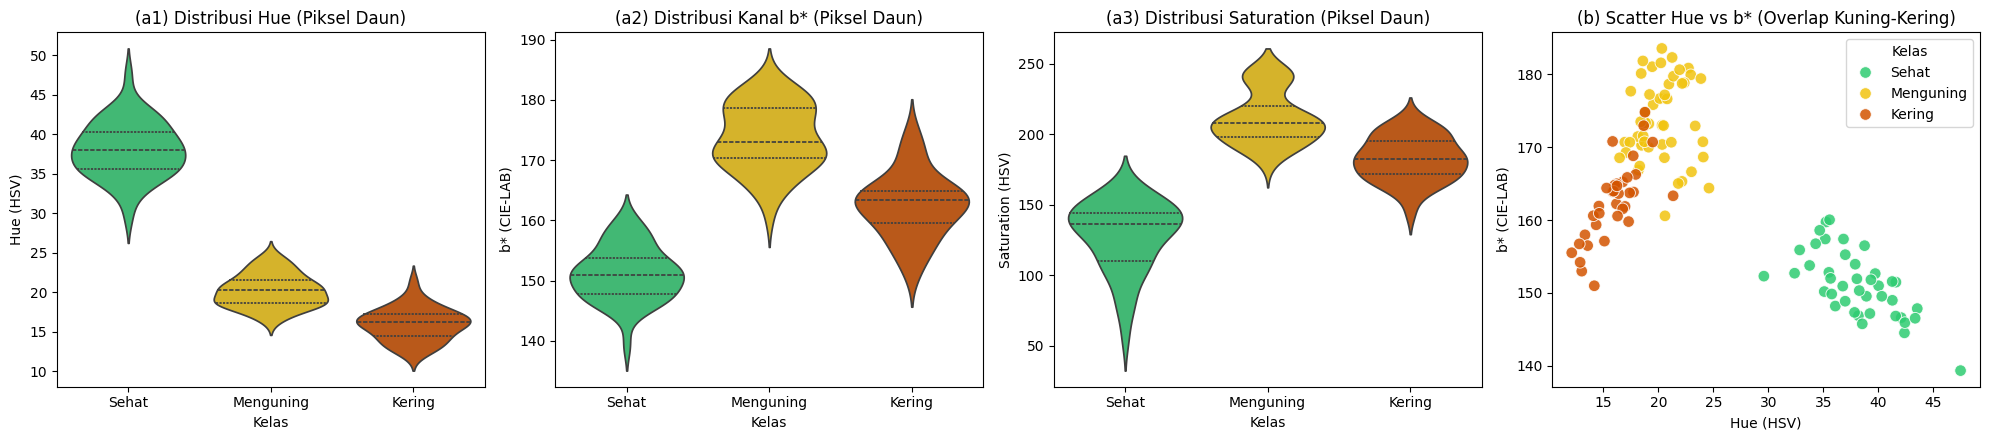

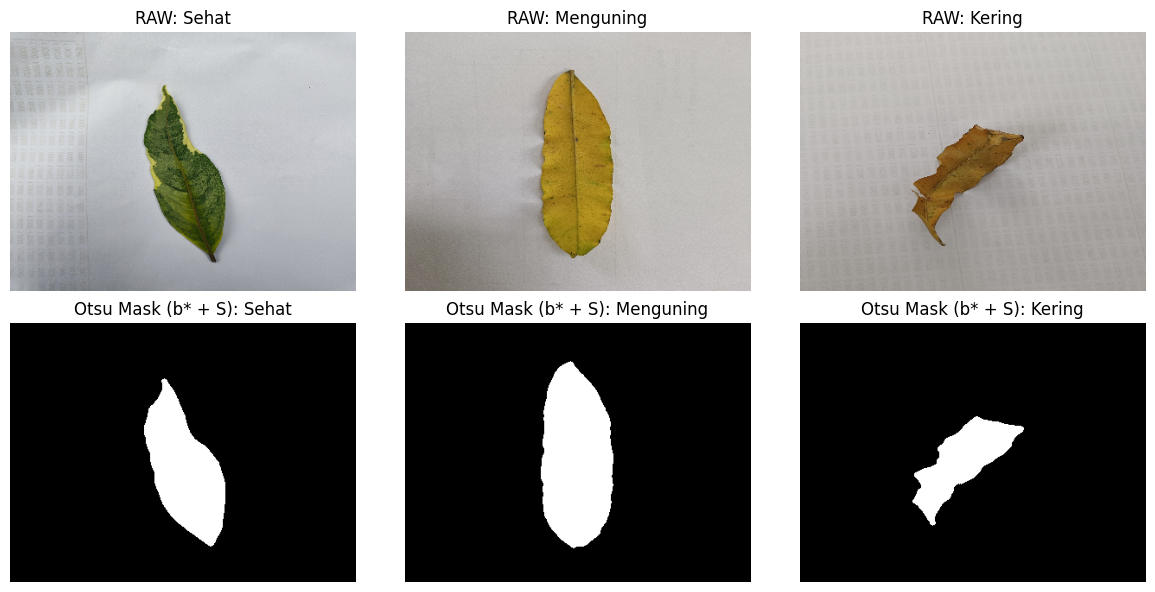

In [39]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

def segment_leaf_otsu_fixed(img_bgr):
    """Segmentasi daun di atas kertas putih menggunakan kanal b* (LAB) dan Saturation (HSV)."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    _, _, b = cv2.split(lab)
    _, s, _ = cv2.split(hsv)

    # Daun (hijau, kuning, maupun cokelat) selalu memiliki nilai b* (kekuningan)
    # dan Saturation (S) yang jauh lebih tinggi daripada alas kertas putih
    _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.bitwise_or(mask_b, mask_s)

    # Operasi morfologi & ambil komponen terbesar (daun utama)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    return mask

leaf_stats, bg_features, bg_labels = [], [], []
sample_vis = {}

for idx, row in df_manifest.iterrows():
    img = cv2.imread(row['filepath'])
    if img is None:
        continue
    img_small = cv2.resize(img, (400, 300))
    mask = segment_leaf_otsu_fixed(img_small)

    hsv = cv2.cvtColor(img_small, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(img_small, cv2.COLOR_BGR2LAB)

    if np.sum(mask > 0) < 500:
        continue

    leaf_stats.append({
        'Kelas': row['label_awal'],
        'Hue (HSV)': np.mean(hsv[:, :, 0][mask > 0]),
        'Saturation (HSV)': np.mean(hsv[:, :, 1][mask > 0]),
        'b* (CIE-LAB)': np.mean(lab[:, :, 2][mask > 0])
    })

    patch_tl, patch_br = img_small[0:40, 0:40], img_small[-40:, -40:]
    patch = np.concatenate([patch_tl.reshape(-1, 3), patch_br.reshape(-1, 3)], axis=0)
    bg_features.append(np.concatenate([np.mean(patch, axis=0), np.std(patch, axis=0)]))
    bg_labels.append(row['label_awal'])

    # Ambil sampel non-variegata untuk visualisasi
    if row['label_awal'] not in sample_vis:
        sample_vis[row['label_awal']] = (img_small, mask)

df_eda = pd.DataFrame(leaf_stats)
palette = {'Sehat': '#2ecc71', 'Menguning': '#f1c40f', 'Kering': '#d35400'}

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
sns.violinplot(data=df_eda, x='Kelas', y='Hue (HSV)', hue='Kelas', palette=palette, legend=False, ax=axes[0], inner='quartile')
axes[0].set_title('(a1) Distribusi Hue (Piksel Daun)')

sns.violinplot(data=df_eda, x='Kelas', y='b* (CIE-LAB)', hue='Kelas', palette=palette, legend=False, ax=axes[1], inner='quartile')
axes[1].set_title('(a2) Distribusi Kanal b* (Piksel Daun)')

sns.violinplot(data=df_eda, x='Kelas', y='Saturation (HSV)', hue='Kelas', palette=palette, legend=False, ax=axes[2], inner='quartile')
axes[2].set_title('(a3) Distribusi Saturation (Piksel Daun)')

sns.scatterplot(data=df_eda, x='Hue (HSV)', y='b* (CIE-LAB)', hue='Kelas', palette=palette, s=70, alpha=0.85, ax=axes[3])
axes[3].set_title('(b) Scatter Hue vs b* (Overlap Kuning-Kering)')
plt.tight_layout()
plt.savefig('Slide8_EDA_Warna_dan_Scatter_Fixed.png', dpi=300)
plt.show()

# Plot (d) dengan vmin=0, vmax=255
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for i, cls_name in enumerate(['Sehat', 'Menguning', 'Kering']):
    if cls_name in sample_vis:
        raw_img, msk = sample_vis[cls_name]
        axes[0, i].imshow(cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB))
        axes[0, i].set_title(f"RAW: {cls_name}")
        axes[0, i].axis('off')

        axes[1, i].imshow(msk, cmap='gray', vmin=0, vmax=255)
        axes[1, i].set_title(f"Otsu Mask (b* + S): {cls_name}")
        axes[1, i].axis('off')
plt.tight_layout()
plt.savefig('Slide8_Contoh_Segmentasi_Otsu_Fixed.png', dpi=300)
plt.show()

In [40]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier

X_bg = np.array(bg_features)
y_bg = np.array(bg_labels)

_, counts = np.unique(y_bg, return_counts=True)
majority = counts.max() / counts.sum()

cv = StratifiedKFold(5, shuffle=True, random_state=42)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
acc = cross_val_score(rf, X_bg, y_bg, cv=cv, scoring='accuracy')

print(f"Background patch acc: {acc.mean():.3f} ± {acc.std():.3f}")
print(f"Chance (1/3): 0.333 | Majority baseline: {majority:.3f}")

Background patch acc: 0.448 ± 0.075
Chance (1/3): 0.333 | Majority baseline: 0.402


### Analisis Keluaran Sel 3:
1. **Kanal $a^*$ vs $b^*+S$:** pada contoh visual, Otsu murni pada kanal $a^*$ tidak memisahkan daun Menguning/Kering dari kertas (diduga karena nilai $a^*$ daun yang kehilangan klorofil mendekati kertas), sedangkan kombinasi $b^*$ dan $S$ menghasilkan siluet yang lebih baik. Ini pengamatan visual; **IoU/Dice belum diukur** terhadap topeng manual (lihat Bagian 8).
2. **Tumpang tindih warna:** plot *Violin* dan *Scatter* menunjukkan kelas Sehat terpisah jelas (Hue 32–46), sedangkan Menguning dan Kering tumpang tindih besar pada `Hue 15–22` dan `b* 160–178`. Ini mengindikasikan bahwa warna saja mungkin kurang memadai untuk Menguning vs Kering; hipotesis ini diuji pada Bagian 12–14.
3. **Uji kebocoran latar (hasil akhir pada Bagian 5):** patch latar Sesi 1+2 menghasilkan akurasi 44,8% ± 5,7% (baseline mayoritas 40,2%, tebakan acak 33,3%). Selisih +4,6 poin berada dalam simpangan baku sehingga tidak meyakinkan. Pada Sesi 1 saja (1 kelas = 1 HP) akurasi 50,6% vs baseline 47,1% (p = 0,032): indikasi awal dengan efek moderat. Sel eksplorasi awal di atas (RF 200 pohon) memberi 44,8% ± 7,5%; angka resmi untuk laporan adalah hasil Bagian 5. Risiko konfounding kelas–perangkat tetap ada secara desain dan diuji langsung dengan LOSO dan pemisahan efek topeng pada Bagian 14.

## 4. Uji Kebocoran Latar Khusus Sesi 1 (Permutation Test)

Tujuan: Pada Sesi 1, setiap kelas dipotret dengan satu HP berbeda, sehingga kelas dan perangkat bercampur. Sel ini menguji apakah patch latar (dua pojok 40×40 px, tanpa daun) saja sudah dapat memprediksi kelas pada Sesi 1. Jika ya, model berisiko belajar ciri kamera atau cahaya, bukan ciri daun.
Metode: Random Forest + Stratified 5-fold pada fitur patch latar (mean dan std RGB) Sesi 1 (N = 85). Permutation test (200 permutasi) menguji apakah akurasi lebih tinggi daripada akurasi pada label yang diacak. Pembanding: majority baseline.

In [41]:
from sklearn.model_selection import permutation_test_score
mask = (df_manifest['sesi'] == 1).values
Xs, ys = X_bg[mask], y_bg[mask]
_, c = np.unique(ys, return_counts=True)
rf = RandomForestClassifier(n_estimators=200, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
score, perm, p = permutation_test_score(rf, Xs, ys, cv=cv, n_permutations=200, random_state=42)
print(f"Sesi 1 saja: acc={score:.3f}, majority={c.max()/c.sum():.3f}, p-permutasi={p:.3f}")

Sesi 1 saja: acc=0.518, majority=0.471, p-permutasi=0.020


In [42]:
print(f"Null permutasi: {perm.mean():.3f} ± {perm.std():.3f}")

Null permutasi: 0.387 ± 0.057


### Analisis Keluaran (uji eksplorasi awal Sesi 1: 200 permutasi, RF 200 pohon)
- **Hasil:** Sesi 1 (N = 85): akurasi 51,8% vs baseline mayoritas 47,1%; p-permutasi = 0,020; null permutasi 0,387 ± 0,057.
- **Interpretasi:** patch latar mengandung sinyal kelas yang lebih besar daripada kebetulan, tetapi selisih dari baseline kecil (+4,7 poin). Ini indikasi awal, bukan bukti kuat, adanya kebocoran perangkat atau cahaya pada Sesi 1.
- **Hubungan dengan Bagian 5:** uji ulang yang lebih ketat (RF 100 pohon, 500 permutasi) memberi 50,6%, p = 0,032. Kedua uji konsisten (efek moderat); **angka resmi untuk laporan dan slide adalah hasil Bagian 5.** Perbedaan angka berasal dari jumlah pohon, jumlah permutasi, dan pengacakan.
- **Keterbatasan:** N kecil, satu model, dua uji tanpa koreksi perbandingan ganda.
- **Implikasi:** mendukung penghapusan latar (segmentasi ROI) dan evaluasi lintas sesi (LOSO), yang dilaporkan di Bagian 14.

## 5. Evaluasi Statistik Bias Background: Gabungan Sesi 1+2 vs Khusus Sesi 1 (Permutation Test)

**Tujuan:**  
Menguji secara statistik apakah potongan pojok kertas latar putih ($40 \times 40$ piksel tanpa objek daun) mengandung sinyal kebocoran identitas kelas (*background/device leakage*) akibat perbedaan karakteristik sensor kamera HP dan waktu pemotretan.

**Metode Evaluasi:**
1. **Evaluasi Gabungan Sesi 1 + Sesi 2 ($N = 127$):** Menggunakan *Random Forest Classifier* (`n_estimators=100`) dengan skema *Stratified 5-Fold Cross-Validation* dan membandingkan akurasinya terhadap *Majority Class Baseline* (proporsi kelas terbanyak `Menguning` = $51/127$ atau $40,2\%$).
2. **Evaluasi Khusus Sesi 1 ($N = 85$, Kondisi 1 Kelas = 1 HP):** Menggunakan `permutation_test_score` sebanyak 500 iterasi pengacakan label untuk menguji apakah akurasi prediksi latar pada Sesi 1 berbeda signifikan secara statistik ($p < 0,05$) dari distribusi kebetulan (*null distribution*).

In [44]:
# === SEL TAMBAHAN: UJI BIAS LATAR SESI 1+2 VS KHUSUS SESI 1 (PERMUTATION TEST) ===
from sklearn.model_selection import StratifiedKFold, cross_val_score, permutation_test_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np

X_all = np.array(bg_features)
y_all = np.array(bg_labels)
sesi_all = df_manifest['sesi'].values

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_rf = RandomForestClassifier(n_estimators=100, random_state=42)

# 1. Evaluasi Gabungan Sesi 1 + Sesi 2 (N = 127)
scores_all = cross_val_score(clf_rf, X_all, y_all, cv=cv5, scoring='accuracy')
maj_all = np.max(np.unique(y_all, return_counts=True)[1]) / len(y_all)

print("=== 1. UJI POTONGAN LATAR GABUNGAN SESI 1+2 (N = 127) ===")
print(f"Akurasi Latar Sesi 1+2 : {scores_all.mean()*100:.1f}% ± {scores_all.std()*100:.1f}%")
print(f"Baseline Mayoritas     : {maj_all*100:.1f}% (Tebakan Acak Seimbang: 33.3%)\n")

# 2. Evaluasi Khusus Sesi 1 (N = 85, 1 Kelas = 1 HP) dengan Uji Permutasi
mask_s1 = (sesi_all == 1)
X_s1, y_s1 = X_all[mask_s1], y_all[mask_s1]
maj_s1 = np.max(np.unique(y_s1, return_counts=True)[1]) / len(y_s1)

score_s1, perm_scores_s1, pvalue_s1 = permutation_test_score(
    clf_rf, X_s1, y_s1, scoring="accuracy", cv=cv5, n_permutations=500, random_state=42
)

print("=== 2. UJI POTONGAN LATAR KHUSUS SESI 1 (N = 85) ===")
print(f"Akurasi Latar Sesi 1   : {score_s1*100:.1f}%")
print(f"Baseline Mayoritas S1  : {maj_s1*100:.1f}%")
print(f"Null Permutasi Acak    : {perm_scores_s1.mean()*100:.1f}%")
print(f"p-value Permutasi      : p = {pvalue_s1:.3f}")

=== 1. UJI POTONGAN LATAR GABUNGAN SESI 1+2 (N = 127) ===
Akurasi Latar Sesi 1+2 : 44.8% ± 5.7%
Baseline Mayoritas     : 40.2% (Tebakan Acak Seimbang: 33.3%)

=== 2. UJI POTONGAN LATAR KHUSUS SESI 1 (N = 85) ===
Akurasi Latar Sesi 1   : 50.6%
Baseline Mayoritas S1  : 47.1%
Null Permutasi Acak    : 38.5%
p-value Permutasi      : p = 0.032


### Analisis Hasil Uji Bias Latar Belakang (Background Patch Test)

Dua temuan utama yang mendasari desain eksperimen:

1. **Gabungan Sesi 1 + Sesi 2 ($N = 127$):**
   * Akurasi prediksi kelas hanya dari patch kertas latar adalah **44,8% ± 5,7%**; *baseline* mayoritas (selalu `Menguning`) **40,2%**; tebakan acak seimbang **33,3%**.
   * Selisih terhadap baseline hanya **+4,6 poin** dan masih dalam simpangan baku ($\pm 5,7$), sehingga efek bias latar pada gabungan dua sesi tidak meyakinkan.

2. **Khusus Sesi 1 ($N = 85$, 1 kelas = 1 HP):**
   * Akurasi **50,6%**, di atas *baseline* Sesi 1 (**47,1%** = 40/85) dan *null* permutasi (**38,5%**), dengan **$p = 0,032$**.
   * **Interpretasi:** ini indikasi awal dengan efek moderat bahwa profil sensor HP (*white balance*, *exposure*, *noise* latar) ikut terekam pada area kertas ketika tiap kelas hanya difoto oleh satu perangkat. Efek mengecil saat digabung dengan Sesi 2, yang konsisten dengan pencampuran perangkat meredam *shortcut*, namun uji ini tidak dapat memastikannya.

**Implikasi:** keputusan desain akhir adalah (a) menghapus latar melalui segmentasi Otsu $b^*+S$ (skenario C2/A) dan (b) mengevaluasi dengan **LOSO** (Bagian 14), karena tidak ada tambahan data (arahan dosen). Hasil Bagian 14: fitur dari citra mentah (A0) dan citra PCD tanpa topeng (C1) runtuh pada LOSO, sedangkan fitur ROI bertopeng (A) bertahan.

# Progress 2

## 6. Inspeksi File Nama Ganda & Pembagian Stratified 5-Fold Split (Anti-Leakage)

**Tujuan:**
1. Memeriksa detail file bernama ganda (`IMG_20261022_155402.jpg`) untuk memastikan apakah keduanya merupakan objek daun yang berbeda yang terpotret pada detik yang sama atau duplikat identik, serta memberikan `id_daun` unik (`LEAF_001` s.d. `LEAF_127`) agar tidak saling menimpa saat ekspor citra.
2. Membagi 127 foto primer asli ke dalam **5-Fold Stratified Cross-Validation (`fold` 0 s.d. 4) SEBELUM proses augmentasi sintetis**. Langkah ini krusial agar citra hasil augmentasi hanya masuk ke *Training Fold* yang sama dengan citra induknya, sehingga mencegah kebocoran data (*data leakage*) ke *Testing Fold*.

In [45]:
from sklearn.model_selection import StratifiedKFold
import cv2
import numpy as np
import pandas as pd

# 1. Inspeksi file dengan nama ganda (IMG_20261022_155402.jpg)
dup_rows = df_manifest[df_manifest['filename'] == 'IMG_20261022_155402.jpg']
print("=== 1. INSPEKSI FILE NAMA GANDA ===")
for idx, r in dup_rows.iterrows():
    img_tmp = cv2.imread(r['filepath'])
    mean_bgr = np.mean(img_tmp, axis=(0, 1)).round(1) if img_tmp is not None else [0, 0, 0]
    print(f"Index {idx} | Folder Kelas: {r['label_awal']:10s} | Resolusi: {r['resolusi']} | Mean BGR: {mean_bgr}")

# 2. Berikan ID Unik (LEAF_001 s.d. LEAF_127) agar nama file output tidak bentrok
df_clean = df_manifest.copy().reset_index(drop=True)
df_clean['id_daun'] = [f"LEAF_{i+1:03d}" for i in range(len(df_clean))]
df_clean['label_final'] = df_clean['label_awal']  # Karena folder Drive sudah disortir manual

# 3. Stratified 5-Fold Split pada 127 Citra Asli SEBELUM Augmentasi
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
df_clean['fold'] = -1
for fold_idx, (_, val_idx) in enumerate(skf.split(df_clean, df_clean['label_final'])):
    df_clean.loc[val_idx, 'fold'] = fold_idx

df_clean.to_csv('split_master_127_original.csv', index=False)

print("\n=== 2. DISTRIBUSI STRATIFIED 5-FOLD PADA 127 CITRA PRIMER ASLI ===")
print(pd.crosstab(df_clean['fold'], df_clean['label_final'], margins=True))

=== 1. INSPEKSI FILE NAMA GANDA ===
Index 72 | Folder Kelas: Menguning  | Resolusi: 3472x4624 | Mean BGR: [173.8 172.6 173.7]
Index 106 | Folder Kelas: Kering     | Resolusi: 4608x3456 | Mean BGR: [167.1 174.2 180.4]

=== 2. DISTRIBUSI STRATIFIED 5-FOLD PADA 127 CITRA PRIMER ASLI ===
label_final  Kering  Menguning  Sehat  All
fold                                      
0                 7         10      9   26
1                 7         11      8   26
2                 7         10      8   25
3                 7         10      8   25
4                 7         10      8   25
All              35         51     41  127


### Analisis Keluaran Sel 6:
- **Penanganan nama ganda:** setiap citra memiliki `id_daun` unik (`LEAF_001` hingga `LEAF_127`), sehingga file bernama sama dari folder berbeda tidak saling menimpa.
- **Partisi 5-fold stratifikasi:** 127 foto asli dibagi ke 5 *fold* (±25–26 foto per *fold*; rasio kelas konsisten: 8–9 Sehat, 10–11 Menguning, 7 Kering). Pembagian di tingkat `id_daun` sebelum augmentasi mencegah variasi sintetis dari foto yang sama muncul di data latih dan uji sekaligus.
- **Batasan:** split ini per **foto**, bukan per daun/pohon/sesi/ponsel (tidak ada ID daun). Foto berbeda dari daun yang sama, atau foto dari sesi dan ponsel yang sama, masih dapat jatuh di latih dan uji. Karena itu evaluasi 5-fold dilengkapi LOSO (Bagian 14).

## 7. Eksplorasi & Perbandingan Metode Preprocessing PCD (Iluminasi, Filtering & CLAHE)

**Tujuan:**  
Menindaklanjuti masukan dosen pada Progress 1 untuk mengeksplorasi variasi *preprocessing* di Colab:
1. **Koreksi iluminasi (gamma pada kanal $L^*$ CIE-LAB):** membandingkan citra asli dengan koreksi gamma (`L* ** γ`; γ<1 mencerahkan). Pipeline akhir memakai γ adaptif (0,8–1,25) menuju kecerahan target.
2. **Denoising:** membandingkan *Gaussian Blur*, *Median Filter*, dan *Bilateral Filter* (pengamatan visual sifat *edge-preserving*).
3. **CLAHE pada $L^*$:** membandingkan `clipLimit` 1.0, 2.0, dan 4.0.

Perbandingan pada bagian ini bersifat **visual pada satu sampel**. Pengaruh kuantitatif PCD terhadap akurasi diuji pada Bagian 12–14.

In [46]:
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# def apply_gamma_lab(img_bgr, gamma=0.85):
#     """Koreksi Gamma khusus pada kanal Luminance (L*) di ruang CIE-LAB."""
#     lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     inv_gamma = 1.0 / gamma
#     table = np.array([((i / 255.0) ** inv_gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
#     l_gamma = cv2.LUT(l, table)
#     return cv2.cvtColor(cv2.merge([l_gamma, a, b]), cv2.COLOR_LAB2BGR)

# def apply_bilateral(img_bgr, d=9, sigma_color=75, sigma_space=75):
#     """Edge-preserving denoising menggunakan Bilateral Filter."""
#     return cv2.bilateralFilter(img_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)

# def apply_clahe_lab(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
#     """Peningkatan kontras lokal pada kanal L* menggunakan CLAHE."""
#     lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
#     l, a, b = cv2.split(lab)
#     clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
#     l_clahe = clahe.apply(l)
#     return cv2.cvtColor(cv2.merge([l_clahe, a, b]), cv2.COLOR_LAB2BGR)

# # Ambil 1 sampel foto daun Kering dari Sesi 1 untuk visualisasi perbandingan PCD
# sample_row = df_clean[df_clean['label_final'] == 'Kering'].iloc[0]
# img_sample = cv2.resize(cv2.imread(sample_row['filepath']), (600, 450))

# # Variasi tahapan PCD
# img_gamma = apply_gamma_lab(img_sample, gamma=0.85)
# img_gauss = cv2.GaussianBlur(img_gamma, (9, 9), 0)
# img_median = cv2.medianBlur(img_gamma, 9)
# img_bilat = apply_bilateral(img_gamma, d=9, sigma_color=75, sigma_space=75)

# img_clahe_1 = apply_clahe_lab(img_bilat, clip_limit=1.0, tile_size=(8, 8))
# img_clahe_2 = apply_clahe_lab(img_bilat, clip_limit=2.0, tile_size=(8, 8))
# img_clahe_4 = apply_clahe_lab(img_bilat, clip_limit=4.0, tile_size=(8, 8))

# # Plot Komparasi 2 Baris x 4 Kolom
# titles = [
#     '(a) RAW Image (Asli)', '(b) Gamma Correction (L*, γ=0.85)',
#     '(c) Gaussian Blur (Tepi Kabur)', '(d) Median Filter (Tekstur Hilang)',
#     '(e) Bilateral Filter (Edge-Preserving)', '(f) CLAHE (clipLimit=1.0)',
#     '(g) CLAHE Optimal (clipLimit=2.0)', '(h) CLAHE Berlebih (clipLimit=4.0)'
# ]
# images = [img_sample, img_gamma, img_gauss, img_median, img_bilat, img_clahe_1, img_clahe_2, img_clahe_4]

# fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
# for ax, im, ttl in zip(axes.flat, images, titles):
#     ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
#     ax.set_title(ttl, fontsize=11, fontweight='bold')
#     ax.axis('off')

# plt.tight_layout()
# plt.savefig('P2_Slide5_6_Komparasi_Metode_PCD.png', dpi=300)
# plt.show()

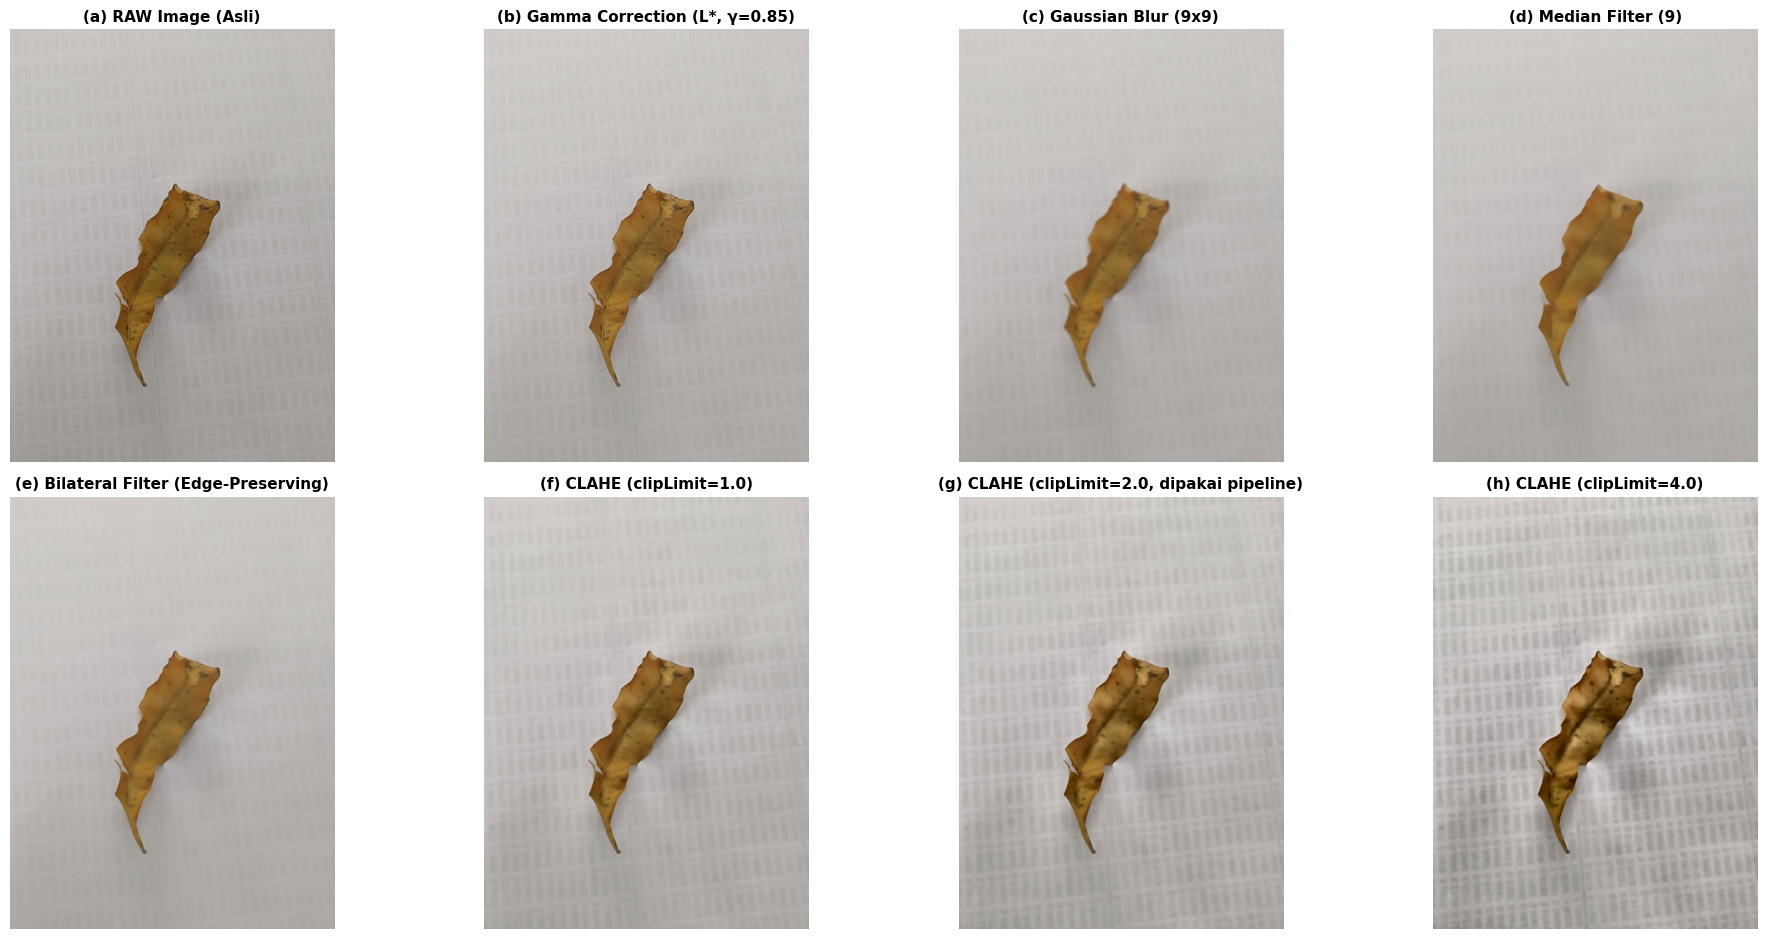

In [47]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def apply_gamma_lab(img_bgr, gamma=0.85):
    """Koreksi Gamma pada kanal L* (CIE-LAB): out = L**gamma. gamma<1 = LEBIH TERANG (v1 salah arah: x**(1/gamma))."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    table = np.array([((i / 255.0) ** gamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
    l_gamma = cv2.LUT(l, table)
    return cv2.cvtColor(cv2.merge([l_gamma, a, b]), cv2.COLOR_LAB2BGR)

def apply_bilateral(img_bgr, d=9, sigma_color=75, sigma_space=75):
    """Edge-preserving denoising menggunakan Bilateral Filter."""
    return cv2.bilateralFilter(img_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)

def apply_clahe_lab(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    """Peningkatan kontras lokal pada kanal L* menggunakan CLAHE."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    l_clahe = clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l_clahe, a, b]), cv2.COLOR_LAB2BGR)

# Ambil 1 sampel foto daun Kering dari Sesi 1 untuk visualisasi perbandingan PCD
sample_row = df_clean[df_clean['label_final'] == 'Kering'].iloc[0]
_im = cv2.imread(sample_row['filepath'])
img_sample = cv2.resize(_im, (600, round(600 * _im.shape[0] / _im.shape[1])))  # rasio aspek dipertahankan

# Variasi tahapan PCD
img_gamma = apply_gamma_lab(img_sample, gamma=0.85)
img_gauss = cv2.GaussianBlur(img_gamma, (9, 9), 0)
img_median = cv2.medianBlur(img_gamma, 9)
img_bilat = apply_bilateral(img_gamma, d=9, sigma_color=75, sigma_space=75)

img_clahe_1 = apply_clahe_lab(img_bilat, clip_limit=1.0, tile_size=(8, 8))
img_clahe_2 = apply_clahe_lab(img_bilat, clip_limit=2.0, tile_size=(8, 8))
img_clahe_4 = apply_clahe_lab(img_bilat, clip_limit=4.0, tile_size=(8, 8))

# Plot Komparasi 2 Baris x 4 Kolom
titles = [
    '(a) RAW Image (Asli)', '(b) Gamma Correction (L*, γ=0.85)',
    '(c) Gaussian Blur (9x9)', '(d) Median Filter (9)',
    '(e) Bilateral Filter (Edge-Preserving)', '(f) CLAHE (clipLimit=1.0)',
    '(g) CLAHE (clipLimit=2.0, dipakai pipeline)', '(h) CLAHE (clipLimit=4.0)'
]
images = [img_sample, img_gamma, img_gauss, img_median, img_bilat, img_clahe_1, img_clahe_2, img_clahe_4]

fig, axes = plt.subplots(2, 4, figsize=(20, 9.5))
for ax, im, ttl in zip(axes.flat, images, titles):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(ttl, fontsize=11, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.savefig('P2_Slide5_6_Komparasi_Metode_PCD.png', dpi=300)
plt.show()

### Analisis Keluaran Sel 7 (perbandingan visual pada SATU sampel — belum kuantitatif)
1. **Koreksi Gamma (perbaikan v2):** Implementasi sebelumnya memakai `x ** (1/γ)` sehingga γ=0,85 justru *menggelapkan* citra. Sekarang `L* ** γ`, jadi γ<1 mencerahkan. Pipeline akhir memakai **γ adaptif** (rentang 0,8–1,25) menuju kecerahan target = median seluruh dataset (sel berikutnya), bukan γ tetap per sesi.
2. **Filtering:** Pada sampel ini Gaussian terlihat mengaburkan tepi dan Median terlihat menghaluskan urat halus; Bilateral ($d=9, \sigma=75$) mempertahankan tepi lebih baik. Ini pengamatan visual satu foto.
3. **CLAHE (`clipLimit = 2.0`):** dipilih secara visual pada satu sampel. CLAHE juga mengangkat pola kotak pada kertas latar. Pilihan ini belum divalidasi secara kuantitatif; dampaknya pada akurasi diuji di Bagian 12 (A0 vs A) dan Bagian 14 (LOSO, McNemar).

In [48]:
# ===== HELPER v2: resize tanpa melar, letterbox, gamma adaptif, target kecerahan =====
WORK_LONG = 800

def resize_long(img, long_side=WORK_LONG):
    """Resize dengan rasio aspek dipertahankan (v1 memaksa 600x450 -> foto potret teregang 1,78x)."""
    h, w = img.shape[:2]; s = long_side / max(h, w)
    return cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)

def letterbox(img, size=224, border=cv2.BORDER_REPLICATE, interp=cv2.INTER_AREA):
    h, w = img.shape[:2]; s = size / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    r = cv2.resize(img, (nw, nh), interpolation=interp)
    t, l = (size - nh) // 2, (size - nw) // 2
    return cv2.copyMakeBorder(r, t, size - nh - t, l, size - nw - l, border, value=0)

def mean_L(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)[:, :, 0].mean() / 255.0

def adaptive_gamma_lab(img_bgr, target, lo=0.8, hi=1.25):
    """out = L**gamma. gamma<1 = lebih terang. Dipilih dari isi citra (bukan dari nomor sesi)."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    m = float(np.clip(lab[:, :, 0].mean() / 255.0, 0.05, 0.95))
    g = float(np.clip(np.log(target) / np.log(m), lo, hi))
    lut = (((np.arange(256) / 255.0) ** g) * 255).astype(np.uint8)
    lab[:, :, 0] = cv2.LUT(lab[:, :, 0], lut)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), g

# Target kecerahan = median seluruh dataset (satu target untuk semua sesi dan kelas)
WORK_IMGS = {i: resize_long(cv2.imread(r['filepath'])) for i, r in df_clean.iterrows()}
TARGET_L = float(np.median([mean_L(im) for im in WORK_IMGS.values()]))
print(f"Target L* (median dataset) = {TARGET_L:.3f}")
print("Rentang mean L* per sesi (sebelum koreksi):")
print(pd.Series({i: mean_L(im) for i, im in WORK_IMGS.items()}).groupby(df_clean['sesi']).describe().round(3))

Target L* (median dataset) = 0.716
Rentang mean L* per sesi (sebelum koreksi):
      count   mean    std    min    25%    50%    75%    max
sesi                                                        
1      85.0  0.711  0.022  0.650  0.695  0.715  0.728  0.757
2      42.0  0.706  0.038  0.589  0.685  0.722  0.733  0.758


### Analisis Keluaran Helper v2 (target kecerahan)
Target L* = median dataset = **0,716**. Rata-rata L* foto asli hampir sama antar sesi (Sesi 1: 0,711 ± 0,022; Sesi 2: 0,706 ± 0,038), sehingga kecerahan bukan pembeda sesi yang kuat dan koreksi gamma hanya melakukan penyesuaian kecil (γ 0,8–1,2). Pengaruh gamma terhadap akurasi tidak diuji terpisah.

## 8. Segmentasi ROI (Otsu Kanal $b^* + S$), Operasi Morfologi, & Isolasi Objek ($224 \times 224$)

**Tujuan:**
1. Menyempurnakan *mask* hasil *Otsu Thresholding* (kanal $b^* + S$) menggunakan operasi morfologi **Opening** (menghilangkan derau titik di latar belakang) dan **Closing** (menutup lubang bercak nekrosis di dalam daun) serta pemilihan *Largest Connected Component*.
2. Melakukan pemotongan kotak pembatas daun (*Bounding Box ROI Cropping*) dengan *padding* persegi proporsional sebelum di-*resize* ke $224 \times 224$ piksel agar bentuk daun lanset yang memanjang tidak terdistorsi/gepeng (*aspect ratio preservation*).

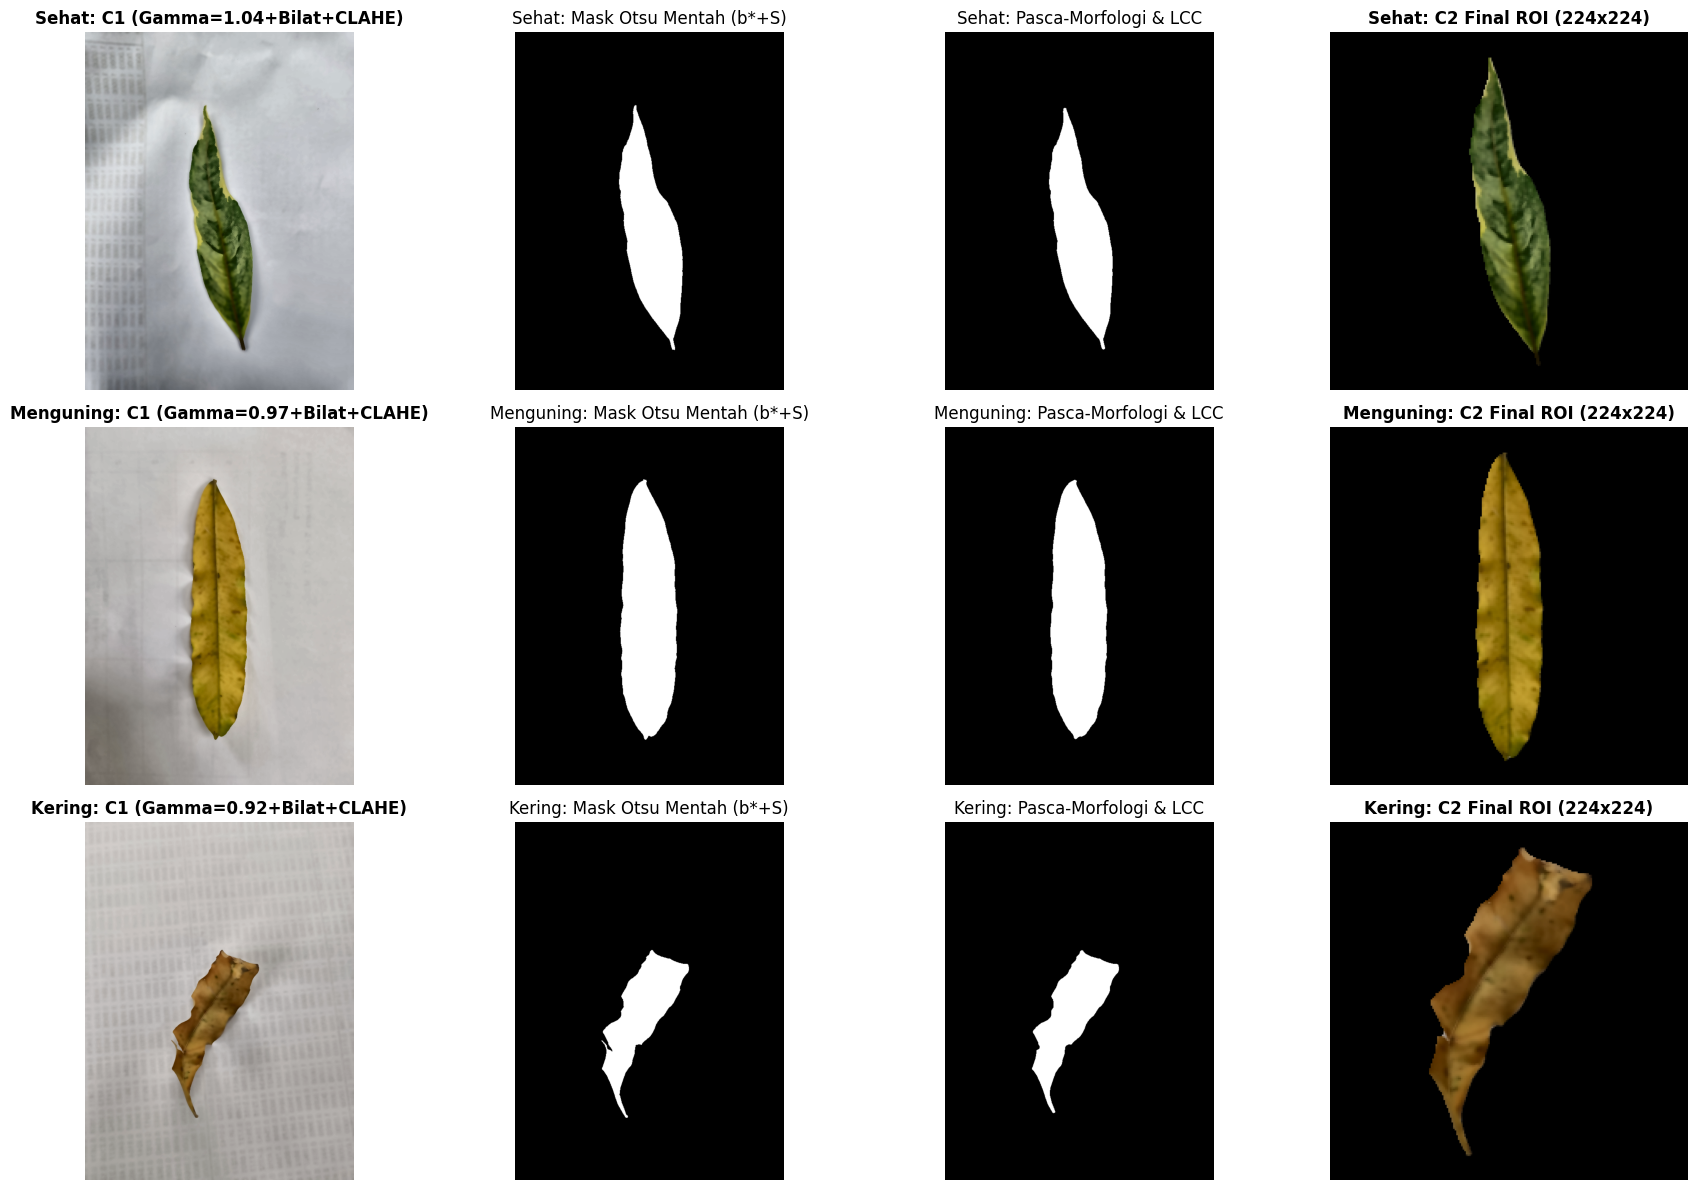

In [49]:
def segment_leaf_otsu_morph(img_bgr):
    """Mengembalikan mask Otsu mentah dan mask bersih pasca-morfologi Opening & Closing."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    _, _, b = cv2.split(lab)
    _, s, _ = cv2.split(hsv)

    _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask_raw = cv2.bitwise_or(mask_b, mask_s)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask_clean = cv2.morphologyEx(mask_raw, cv2.MORPH_OPEN, kernel, iterations=1)
    mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel, iterations=2)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_clean, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask_clean = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    return mask_raw, mask_clean

def crop_roi_with_padding(img_bgr, mask, target_size=(224, 224), pad_ratio=0.08):
    """Crop ROI daun dengan padding persegi hitam agar rasio geometri daun tidak penyok saat resize."""
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return cv2.resize(img_bgr, target_size), cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)

    x1, x2 = np.min(xs), np.max(xs)
    y1, y2 = np.min(ys), np.max(ys)
    h_box, w_box = y2 - y1, x2 - x1
    max_side = int(max(h_box, w_box) * (1.0 + 2 * pad_ratio))

    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    half = max_side // 2

    img_masked = cv2.bitwise_and(img_bgr, img_bgr, mask=mask)
    h_img, w_img = img_bgr.shape[:2]

    canvas_img = np.zeros((max_side, max_side, 3), dtype=np.uint8)
    canvas_mask = np.zeros((max_side, max_side), dtype=np.uint8)

    src_x1, src_y1 = max(0, cx - half), max(0, cy - half)
    src_x2, src_y2 = min(w_img, cx - half + max_side), min(h_img, cy - half + max_side)

    dst_x1, dst_y1 = src_x1 - (cx - half), src_y1 - (cy - half)
    dst_x2, dst_y2 = dst_x1 + (src_x2 - src_x1), dst_y1 + (src_y2 - src_y1)

    canvas_img[dst_y1:dst_y2, dst_x1:dst_x2] = img_masked[src_y1:src_y2, src_x1:src_x2]
    canvas_mask[dst_y1:dst_y2, dst_x1:dst_x2] = mask[src_y1:src_y2, src_x1:src_x2]

    roi_resized = cv2.resize(canvas_img, target_size, interpolation=cv2.INTER_AREA)
    mask_resized = cv2.resize(canvas_mask, target_size, interpolation=cv2.INTER_NEAREST)
    # Pastikan piksel di luar mask mutlak hitam [0, 0, 0] pasca-interpolasi resize
    roi_resized = cv2.bitwise_and(roi_resized, roi_resized, mask=mask_resized)
    return roi_resized, mask_resized

# Visualisasi 3 Kelas (Sehat, Menguning, Kering) menggunakan pipeline v2 (tanpa melar & gamma adaptif)
fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for r_idx, cls_name in enumerate(['Sehat', 'Menguning', 'Kering']):
    idx_c = df_clean.index[df_clean['label_final'] == cls_name][0]
    im_work = WORK_IMGS[idx_c]
    im_gamma, gv = adaptive_gamma_lab(im_work, TARGET_L)
    im_c1 = apply_clahe_lab(apply_bilateral(im_gamma), clip_limit=2.0)
    m_raw, m_clean = segment_leaf_otsu_morph(im_c1)
    im_c2_roi, _ = crop_roi_with_padding(im_c1, m_clean, target_size=(224, 224))

    axes[r_idx, 0].imshow(cv2.cvtColor(im_c1, cv2.COLOR_BGR2RGB))
    axes[r_idx, 0].set_title(f"{cls_name}: C1 (Gamma={gv:.2f}+Bilat+CLAHE)", fontweight='bold')
    axes[r_idx, 1].imshow(m_raw, cmap='gray', vmin=0, vmax=255)
    axes[r_idx, 1].set_title(f"{cls_name}: Mask Otsu Mentah (b*+S)")
    axes[r_idx, 2].imshow(m_clean, cmap='gray', vmin=0, vmax=255)
    axes[r_idx, 2].set_title(f"{cls_name}: Pasca-Morfologi & LCC")
    axes[r_idx, 3].imshow(cv2.cvtColor(im_c2_roi, cv2.COLOR_BGR2RGB))
    axes[r_idx, 3].set_title(f"{cls_name}: C2 Final ROI (224x224)", fontweight='bold')
    for c_idx in range(4):
        axes[r_idx, c_idx].axis('off')

plt.tight_layout()
plt.savefig('P2_Slide7_Segmentasi_Morfologi_dan_ROI.png', dpi=300)
plt.show()

### Analisis Keluaran Sel 8 (3 contoh, satu per kelas — belum dievaluasi terhadap topeng manual)
- **Morfologi dan LCC:** Pada kolom kedua, topeng Otsu mentah dapat menyisakan derau di area kertas (bayangan lipatan, tulisan tembus). *Opening-Closing* elips $7 \times 7$ dan komponen terhubung terbesar (LCC) membersihkan sebagian besar derau tersebut pada ketiga contoh ini.
- **Geometri ROI (kolom 4):** *Bounding box* dengan padding persegi memusatkan daun tanpa mengubah rasio panjang-lebar. Kualitas topeng **belum diukur** terhadap topeng manual; IoU/Dice pada ≈20 foto (Otsu b*+S vs a* vs K-Means vs GrabCut) ditambahkan di sel evaluasi segmentasi di bawah. Klaim bahwa kanal $a^*$ gagal harus dikonfirmasi oleh angka tersebut.

In [50]:
# ===== E7: EVALUASI SEGMENTASI TERHADAP TOPENG MANUAL (isi MANUAL_MASK_DIR dulu) =====
# Siapkan ~20 foto (campur kelas & sesi). Topeng manual: PNG biner (putih = daun), nama file = id_daun, mis. LEAF_012.png
# Buat dengan Labelme/GIMP/CVAT; simpan di folder di Drive lalu isi path berikut.
MANUAL_MASK_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Manual_Masks'

def iou_dice(pred, gt):
    p, g = pred > 0, gt > 0
    inter = np.logical_and(p, g).sum(); union = np.logical_or(p, g).sum()
    return inter / max(union, 1), 2 * inter / max(p.sum() + g.sum(), 1)

def seg_a_star(img):                      # pembanding: Otsu pada a* (kanal hijau-merah)
    a = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 1]
    _, m = cv2.threshold(a, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU); return m

def seg_kmeans(img, k=3):                 # pembanding: K-Means warna (a*,b*) lalu klaster paling "daun" = jarak terjauh dari pusat kertas
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 1:].reshape(-1, 2).astype(np.float32)
    _, lbl, cen = cv2.kmeans(lab, k, None, (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0), 3, cv2.KMEANS_PP_CENTERS)
    border = np.concatenate([lbl.reshape(img.shape[:2])[0], lbl.reshape(img.shape[:2])[-1]])
    bg = np.bincount(border.astype(int), minlength=k).argmax()
    return np.where(lbl.reshape(img.shape[:2]) != bg, 255, 0).astype(np.uint8)

def seg_grabcut(img):                     # pembanding: GrabCut dengan kotak awal 5% dari tepi
    h, w = img.shape[:2]; m = np.zeros((h, w), np.uint8); bgd = np.zeros((1, 65)); fgd = np.zeros((1, 65))
    cv2.grabCut(img, m, (int(.05*w), int(.05*h), int(.9*w), int(.9*h)), bgd, fgd, 3, cv2.GC_INIT_WITH_RECT)
    return np.where((m == 1) | (m == 3), 255, 0).astype(np.uint8)

import glob, os
rows = []
for p in sorted(glob.glob(os.path.join(MANUAL_MASK_DIR, '*.png'))):
    lid = os.path.splitext(os.path.basename(p))[0]
    idx = df_clean.index[df_clean['id_daun'] == lid]
    if len(idx) == 0: continue
    idx = idx[0]; im = WORK_IMGS[idx]; g, _ = adaptive_gamma_lab(im, TARGET_L)
    c1 = apply_clahe_lab(apply_bilateral(g), 2.0)
    gt = cv2.resize(cv2.imread(p, 0), (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST)
    for nm, fn in {'Otsu b*+S (pipeline)': lambda: segment_leaf_otsu_morph(c1)[1], 'Otsu a*': lambda: seg_a_star(c1),
                   'K-Means (a*,b*)': lambda: seg_kmeans(c1), 'GrabCut': lambda: seg_grabcut(im)}.items():
        i_, d_ = iou_dice(fn(), gt)
        rows.append(dict(id_daun=lid, kelas=df_clean.loc[idx, 'label_final'], sesi=df_clean.loc[idx, 'sesi'], metode=nm, IoU=i_, Dice=d_))
df_seg = pd.DataFrame(rows)
if len(df_seg):
    print(df_seg.groupby('metode')[['IoU', 'Dice']].agg(['mean', 'std']).round(3))
    print("\nPer kelas (IoU):"); print(df_seg.pivot_table(index='metode', columns='kelas', values='IoU', aggfunc='mean').round(3))
else:
    print("Belum ada topeng manual di", MANUAL_MASK_DIR)

Belum ada topeng manual di /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Manual_Masks


## 9. Sintesis Variasi Data melalui Multi-Augmentasi

**Prinsip:** (1) split dilakukan SEBELUM augmentasi dan uji hanya pada foto asli; (2) **satu pool transformasi yang sama untuk semua kelas**, kelas hanya berbeda pada *jumlah* variasi (Sehat 5, Menguning 4, Kering 6 citra per foto asli), agar jenis augmentasi tidak bisa menjadi petunjuk kelas; (3) augmentasi diterapkan pada citra penuh sebelum crop ROI sehingga ujung daun tidak terpotong; (4) Hue dan Saturation tidak diubah karena selisih saturasi Menguning vs Kering hanya ≈12%; hanya kecerahan ±8%.

Pool 7 transformasi: `hflip`, `vflip_rot90`, `rot25` (skala 0,95), `rot135` (skala 0,90), `rotm20_flip` (flip + rotasi −20°), `bright_up` (V ×1,08), `bright_down` (V ×0,92).
Citra sintetis bukan sampel independen: **jumlah sampel efektif tetap 127**.

In [51]:
# def augment_image_and_mask(img_bgr, mask, aug_type):
#     """Menghasilkan citra dan mask sintetis dari berbagai kombinasi augmentasi."""
#     h, w = img_bgr.shape[:2]
#     out_img = img_bgr.copy()
#     out_mask = mask.copy()
#     # Deteksi apakah gambar adalah skenario C2 (latar belakang sudah dihapus/hitam)
#     is_masked_bg = (np.any(mask == 0) and np.mean(img_bgr[mask == 0]) < 1.0)
#     border_mode_img = cv2.BORDER_CONSTANT if is_masked_bg else cv2.BORDER_REFLECT_101

#     if aug_type == 'hflip':
#         out_img = cv2.flip(out_img, 1)
#         out_mask = cv2.flip(out_mask, 1)

#     elif aug_type == 'vflip_rot90':
#         out_img = cv2.rotate(cv2.flip(out_img, 0), cv2.ROTATE_90_CLOCKWISE)
#         out_mask = cv2.rotate(cv2.flip(out_mask, 0), cv2.ROTATE_90_CLOCKWISE)

#     elif aug_type == 'rot25_scale':
#         M = cv2.getRotationMatrix2D((w // 2, h // 2), angle=25, scale=1.08)
#         out_img = cv2.warpAffine(out_img, M, (w, h), borderMode=border_mode_img, borderValue=(0,0,0))
#         out_mask = cv2.warpAffine(out_mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

#     elif aug_type == 'color_jitter_combo':
#         out_img = cv2.flip(out_img, 1)
#         out_mask = cv2.flip(out_mask, 1)
#         M = cv2.getRotationMatrix2D((w // 2, h // 2), angle=-20, scale=0.95)
#         out_img = cv2.warpAffine(out_img, M, (w, h), borderMode=border_mode_img, borderValue=(0,0,0))
#         out_mask = cv2.warpAffine(out_mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

#         hsv = cv2.cvtColor(out_img, cv2.COLOR_BGR2HSV).astype(np.float32)
#         hsv[:, :, 1] = np.clip(hsv[:, :, 1] * 1.10, 0, 255)  # +10% Saturation
#         hsv[:, :, 2] = np.clip(hsv[:, :, 2] * 0.90, 0, 255)  # -10% Brightness
#         out_img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

#     elif aug_type == 'rot135_bright':
#         M = cv2.getRotationMatrix2D((w // 2, h // 2), angle=135, scale=1.05)
#         out_img = cv2.warpAffine(out_img, M, (w, h), borderMode=border_mode_img, borderValue=(0,0,0))
#         out_mask = cv2.warpAffine(out_mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

#         hsv = cv2.cvtColor(out_img, cv2.COLOR_BGR2HSV).astype(np.float32)
#         hsv[:, :, 2] = np.clip(hsv[:, :, 2] * 1.12, 0, 255)  # +12% Brightness
#         out_img = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

#     # Pastikan area di luar mask selalu hitam bersih tanpa pantulan pojok
#     if is_masked_bg:
#         out_img = cv2.bitwise_and(out_img, out_img, mask=out_mask)

#     return out_img, out_mask

# # Visualisasi Contoh 1 Daun Asli + 5 Variasi Sintetisnya untuk PPT Slide 4
# _, m_clean_sample = segment_leaf_otsu_morph(img_clahe_2)
# roi_orig, mask_orig = crop_roi_with_padding(img_clahe_2, m_clean_sample, target_size=(224, 224))

# aug_types_demo = ['orig', 'hflip', 'vflip_rot90', 'rot25_scale', 'color_jitter_combo', 'rot135_bright']
# aug_titles_demo = [
#     'Original ROI (Asli)', 'Aug 1: Horizontal Flip', 'Aug 2: V-Flip + Rot 90°',
#     'Aug 3: Rot 25° + Scale 1.08x', 'Aug 4: Flip + Rot -20° + Color Jitter', 'Aug 5: Rot 135° + Bright +12%'
# ]

# fig, axes = plt.subplots(1, 6, figsize=(20, 3.8))
# for ax, a_type, a_title in zip(axes, aug_types_demo, aug_titles_demo):
#     if a_type == 'orig':
#         vis_im = roi_orig
#     else:
#         vis_im, _ = augment_image_and_mask(roi_orig, mask_orig, a_type)
#     ax.imshow(cv2.cvtColor(vis_im, cv2.COLOR_BGR2RGB))
#     ax.set_title(a_title, fontsize=10, fontweight='bold')
#     ax.axis('off')

# plt.tight_layout()
# plt.savefig('P2_Slide4_Contoh_Variasi_Augmentasi.png', dpi=300)
# plt.show()

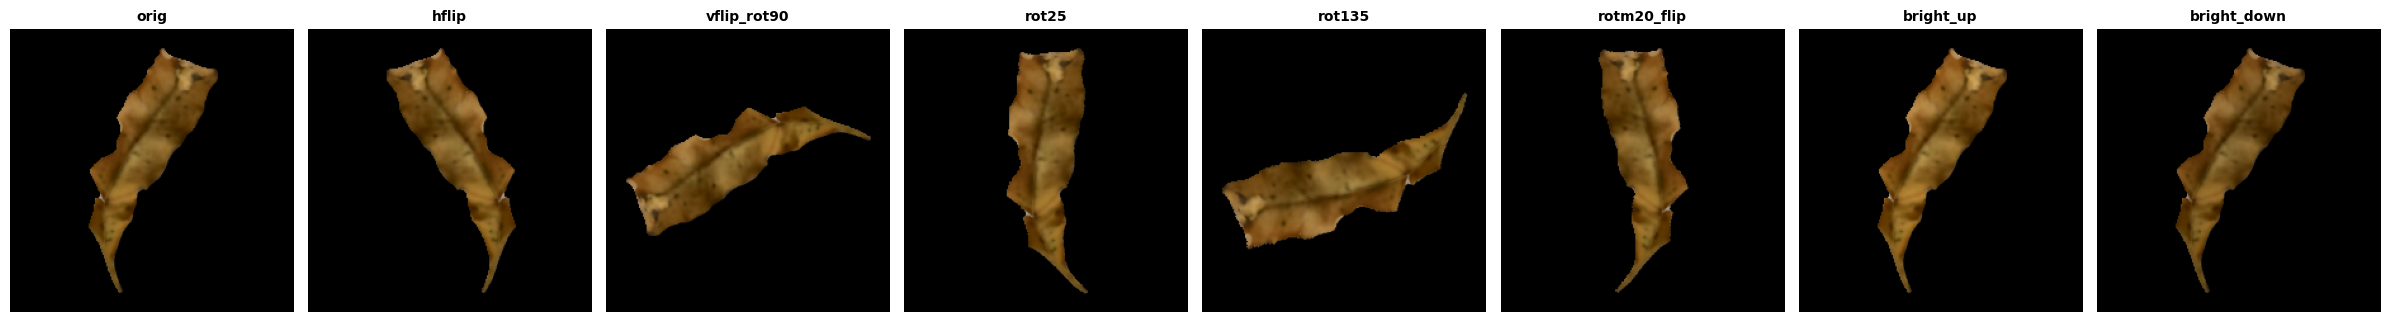

In [52]:
AUG_POOL = ['hflip', 'vflip_rot90', 'rot25', 'rot135', 'rotm20_flip', 'bright_up', 'bright_down']
N_TOTAL  = {'Sehat': 5, 'Menguning': 4, 'Kering': 6}      # jumlah citra per foto asli (asli + sintetis)

def _affine(im, ang, scale, interp, border):
    h, w = im.shape[:2]
    return cv2.warpAffine(im, cv2.getRotationMatrix2D((w / 2, h / 2), ang, scale), (w, h), flags=interp, borderMode=border)

def _scale_v(img, f):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV).astype(np.float32)
    hsv[:, :, 2] = np.clip(hsv[:, :, 2] * f, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2BGR)

def apply_variant(raw, c1, mask, name):
    """Augmentasi pada citra PENUH (sebelum crop ROI). Hanya geometri + kecerahan ±8%."""
    if name == 'orig':
        return raw, c1, mask
    def geo(im, interp=cv2.INTER_LINEAR, border=cv2.BORDER_REPLICATE):
        if name == 'hflip':       return cv2.flip(im, 1)
        if name == 'vflip_rot90': return cv2.rotate(cv2.flip(im, 0), cv2.ROTATE_90_CLOCKWISE)
        if name == 'rot25':       return _affine(im, 25, 0.95, interp, border)
        if name == 'rot135':      return _affine(im, 135, 0.90, interp, border)
        if name == 'rotm20_flip': return _affine(cv2.flip(im, 1), -20, 0.95, interp, border)
        return im
    r, c = geo(raw), geo(c1)
    m = geo(mask, cv2.INTER_NEAREST, cv2.BORDER_CONSTANT)
    if name in ('bright_up', 'bright_down'):
        f = 1.08 if name == 'bright_up' else 0.92
        r, c = _scale_v(r, f), _scale_v(c, f)
    return r, c, m

def choose_variants(leaf_index, label, seed=42):
    """Semua kelas memakai pool yang SAMA; kelas hanya berbeda pada JUMLAH variasi."""
    rng = np.random.default_rng(seed + leaf_index)
    return ['orig'] + [str(v) for v in rng.choice(AUG_POOL, size=N_TOTAL[label] - 1, replace=False)]

# Demo: 1 foto Kering asli + 7 variasi (ROI C2 224x224)
_i = df_clean.index[df_clean['label_final'] == 'Kering'][0]
w0 = WORK_IMGS[_i]; g0, _ = adaptive_gamma_lab(w0, TARGET_L)
c10 = apply_clahe_lab(apply_bilateral(g0), 2.0); _, mk0 = segment_leaf_otsu_morph(c10)
fig, axes = plt.subplots(1, 8, figsize=(24, 3.6))
for ax, v in zip(axes, ['orig'] + AUG_POOL):
    _, c_t, m_t = apply_variant(w0, c10, mk0, v)
    roi, _ = crop_roi_with_padding(c_t, m_t, target_size=(224, 224))
    ax.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)); ax.set_title(v, fontsize=10, fontweight='bold'); ax.axis('off')
plt.tight_layout(); plt.savefig('P2_Slide8_Contoh_Variasi_Augmentasi.png', dpi=300); plt.show()

### Analisis Keluaran Sel 9
- **Variasi yang dihasilkan:** orientasi (0°, 25°, 90°, 135°, −20°), pencerminan, skala, dan kecerahan ±8%. Ujung daun tidak terpotong karena transformasi dilakukan sebelum crop ROI.
- **Label warna dilindungi:** Hue dan Saturation tidak diubah. Alasannya kuantitatif: selisih saturasi rata-rata Menguning vs Kering hanya ≈12%, sehingga *color jitter* pada kanal S berisiko memindahkan sampel melewati batas kelas.
- **Keterbatasan:** ini simulasi variasi geometri/kecerahan, bukan variasi nyata (cahaya, sisi bawah daun, spesies lain). Efek pada akurasi dilaporkan di Bagian 12 dengan simpangan baku.

## 10. Generate Dataset v2 ($N = 619$) & Ekspor `dataset_master_p2.csv`

**Tujuan:**
Menjalankan pipeline PCD v2 dan multi-augmentasi pada seluruh 127 foto primer (`41 Sehat : 51 Menguning : 35 Kering`):
- **Sehat:** $41 \text{ asli} \times 5 = 205$ citra
- **Menguning:** $51 \text{ asli} \times 4 = 204$ citra
- **Kering:** $35 \text{ asli} \times 6 = 210$ citra
- **Total: 619 citra**, disimpan dalam folder `Dataset_P2_Processed_v2` (format PNG lossless) dalam 4 subfolder `A0_raw`, `C1_pcd_nomask`, `C2_pcd_masked`, `masks`, beserta `dataset_master_p2.csv` (kolom tambahan `gamma_used`, `resolusi`).

Folder v1 tidak dipakai lagi dan seluruh angka dari v1 tidak boleh dikutip.

In [53]:
# import os
# from tqdm import tqdm

# OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed'
# for sub in ['A0_raw', 'C1_pcd_nomask', 'C2_pcd_masked', 'masks']:
#     for cls_name in ['Sehat', 'Menguning', 'Kering']:
#         os.makedirs(os.path.join(OUT_BASE, sub, cls_name), exist_ok=True)

# # Resep kuota augmentasi per kelas agar distribusi akhir seimbang (~205 : 204 : 210)
# aug_recipes = {
#     'Sehat':     ['orig', 'hflip', 'vflip_rot90', 'rot25_scale', 'color_jitter_combo'],
#     'Menguning': ['orig', 'hflip', 'rot25_scale', 'color_jitter_combo'],
#     'Kering':    ['orig', 'hflip', 'vflip_rot90', 'rot25_scale', 'color_jitter_combo', 'rot135_bright']
# }

# master_records = []

# print("Memproses 127 citra asli menjadi 619 citra (A0, C1, C2, dan Mask)...")
# for idx, row in tqdm(df_clean.iterrows(), total=len(df_clean)):
#     img_bgr = cv2.imread(row['filepath'])
#     if img_bgr is None:
#         continue

#     cls_name = row['label_final']
#     sesi = row['sesi']
#     leaf_id = row['id_daun']
#     fold = row['fold']

#     # Jalankan tahapan PCD
#     img_work = cv2.resize(img_bgr, (600, 450))
#     gamma_val = 0.85 if sesi == 1 else 1.0
#     img_c1_full = apply_clahe_lab(apply_bilateral(apply_gamma_lab(img_work, gamma=gamma_val)), clip_limit=2.0)
#     _, mask_full = segment_leaf_otsu_morph(img_c1_full)

#     # Siapkan versi 224x224 untuk A0 (Raw), C1 (PCD No-Mask), dan C2 (PCD Masked ROI)
#     raw_224 = cv2.resize(img_work, (224, 224), interpolation=cv2.INTER_AREA)
#     c1_224 = cv2.resize(img_c1_full, (224, 224), interpolation=cv2.INTER_AREA)
#     mask_full_224 = cv2.resize(mask_full, (224, 224), interpolation=cv2.INTER_NEAREST)
#     c2_roi_224, mask_roi_224 = crop_roi_with_padding(img_c1_full, mask_full, target_size=(224, 224))

#     for aug_name in aug_recipes[cls_name]:
#         is_aug = 0 if aug_name == 'orig' else 1
#         sample_id = f"{leaf_id}_{aug_name}"
#         fname_out = f"{sample_id}.jpg"
#         fmask_out = f"{sample_id}.png"

#         if aug_name == 'orig':
#             r_img, c1_img, c2_img, m_img = raw_224, c1_224, c2_roi_224, mask_roi_224
#         else:
#             r_img, _ = augment_image_and_mask(raw_224, mask_full_224, aug_name)
#             c1_img, _ = augment_image_and_mask(c1_224, mask_full_224, aug_name)
#             c2_img, m_img = augment_image_and_mask(c2_roi_224, mask_roi_224, aug_name)

#         p_a0 = os.path.join(OUT_BASE, 'A0_raw', cls_name, fname_out)
#         p_c1 = os.path.join(OUT_BASE, 'C1_pcd_nomask', cls_name, fname_out)
#         p_c2 = os.path.join(OUT_BASE, 'C2_pcd_masked', cls_name, fname_out)
#         p_mk = os.path.join(OUT_BASE, 'masks', cls_name, fmask_out)

#         cv2.imwrite(p_a0, r_img)
#         cv2.imwrite(p_c1, c1_img)
#         cv2.imwrite(p_c2, c2_img)
#         cv2.imwrite(p_mk, m_img)

#         master_records.append({
#             'sample_id': sample_id,
#             'parent_id': leaf_id,
#             'original_filename': row['filename'],
#             'label': cls_name,
#             'sesi': sesi,
#             'fold': fold,
#             'is_augmented': is_aug,
#             'aug_type': aug_name,
#             'path_A0_raw': p_a0,
#             'path_C1_nomask': p_c1,
#             'path_C2_masked': p_c2,
#             'path_mask': p_mk
#         })

# df_master_p2 = pd.DataFrame(master_records)
# csv_master_path = os.path.join(OUT_BASE, 'dataset_master_p2.csv')
# df_master_p2.to_csv(csv_master_path, index=False)
# df_master_p2.to_csv('dataset_master_p2.csv', index=False)

# print("\n=== REKAPITULASI DATASET FINAL PROGRESS 2 (ASLI VS AUGMENTASI) ===")
# print(pd.crosstab(df_master_p2['label'], df_master_p2['is_augmented'], rownames=['Kelas'], colnames=['Is_Augmented (0=Asli, 1=Sintetis)'], margins=True))
# print(f"\nSukses! Seluruh citra dan file '{csv_master_path}' siap digunakan oleh Mahasiswa 2 (ML) & Mahasiswa 3 (DL).")

In [54]:
import os
from tqdm import tqdm
OUT_V2 = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2'

def run_generate_v2(df_clean, out_base):
    for sub in ['A0_raw', 'C1_pcd_nomask', 'C2_pcd_masked', 'masks']:
        for c in N_TOTAL: os.makedirs(os.path.join(out_base, sub, c), exist_ok=True)
    recs = []
    for idx, row in tqdm(df_clean.iterrows(), total=len(df_clean)):
        w, lab_ = WORK_IMGS[idx], row['label_final']
        g, gv = adaptive_gamma_lab(w, TARGET_L)
        c1 = apply_clahe_lab(apply_bilateral(g), clip_limit=2.0)
        _, mask = segment_leaf_otsu_morph(c1)
        for v in choose_variants(idx, lab_):
            r_t, c_t, m_t = apply_variant(w, c1, mask, v)
            a0 = letterbox(r_t); c1_224 = letterbox(c_t)
            c2, mk = crop_roi_with_padding(c_t, m_t, target_size=(224, 224))
            sid = f"{row['id_daun']}_{v}"
            paths = {s: os.path.join(out_base, s, lab_, sid + '.png') for s in ['A0_raw', 'C1_pcd_nomask', 'C2_pcd_masked', 'masks']}
            cv2.imwrite(paths['A0_raw'], a0); cv2.imwrite(paths['C1_pcd_nomask'], c1_224)
            cv2.imwrite(paths['C2_pcd_masked'], c2); cv2.imwrite(paths['masks'], mk)
            recs.append(dict(sample_id=sid, parent_id=row['id_daun'], original_filename=row['filename'], label=lab_,
                             sesi=row['sesi'], fold=row['fold'], is_augmented=int(v != 'orig'), aug_type=v,
                             gamma_used=round(gv, 3), resolusi=row['resolusi'],
                             path_A0_raw=paths['A0_raw'], path_C1_nomask=paths['C1_pcd_nomask'],
                             path_C2_masked=paths['C2_pcd_masked'], path_mask=paths['masks']))
    dfm = pd.DataFrame(recs)
    dfm.to_csv(os.path.join(out_base, 'dataset_master_p2.csv'), index=False)
    dfm.to_csv('dataset_master_p2.csv', index=False)
    return dfm

def get_fold(df, k):
    test = df[(df.fold == k) & (df.is_augmented == 0)]          # uji: HANYA foto asli
    train = df[df.fold != k]                                     # latih: asli + sintetis
    assert set(train.parent_id).isdisjoint(set(test.parent_id)), 'KEBOCORAN parent_id'
    return train, test

def get_loso(df, train_sesi):
    train = df[df.sesi == train_sesi]
    test = df[(df.sesi != train_sesi) & (df.is_augmented == 0)]
    assert set(train.parent_id).isdisjoint(set(test.parent_id)), 'KEBOCORAN parent_id'
    return train, test

df_master_p2 = run_generate_v2(df_clean, OUT_V2)

print("\n=== REKAPITULASI DATASET v2 (ASLI VS SINTETIS) ===")
print(pd.crosstab(df_master_p2['label'], df_master_p2['is_augmented'], rownames=['Kelas'], colnames=['0=Asli, 1=Sintetis'], margins=True))
print("\nAugmentasi per kelas (HARUS memakai pool yang sama; tidak ada jenis khusus satu kelas):")
print(pd.crosstab(df_master_p2['aug_type'], df_master_p2['label']))
print("\nGamma terpakai per sesi (bukan konstan per sesi):")
print(df_master_p2[df_master_p2.is_augmented == 0].groupby('sesi')['gamma_used'].describe().round(3))

100%|██████████| 127/127 [00:49<00:00,  2.55it/s]


=== REKAPITULASI DATASET v2 (ASLI VS SINTETIS) ===
0=Asli, 1=Sintetis    0    1  All
Kelas                            
Kering               35  175  210
Menguning            51  153  204
Sehat                41  164  205
All                 127  492  619

Augmentasi per kelas (HARUS memakai pool yang sama; tidak ada jenis khusus satu kelas):
label        Kering  Menguning  Sehat
aug_type                             
bright_down      29         22     23
bright_up        26         25     24
hflip            22         22     20
orig             35         51     41
rot135           25         24     27
rot25            26         20     24
rotm20_flip      22         18     26
vflip_rot90      25         22     20

Gamma terpakai per sesi (bukan konstan per sesi):
      count   mean    std  min    25%    50%    75%    max
sesi                                                      
1      85.0  0.987  0.088  0.8  0.919  0.993  1.051  1.197
2      42.0  0.987  0.113  0.8  0.883  1.026  1

### Analisis Keluaran Sel 10
- **Distribusi:** 205 Sehat : 204 Menguning : 210 Kering (asli 41/51/35 + sintetis 164/153/175). Ini hasil duplikasi variasi dari 127 foto, bukan 619 sampel independen; sampel efektif tetap 127.
- **Tidak ada petunjuk dari jenis augmentasi:** tabel `aug_type × label` menunjukkan ketujuh transformasi muncul di ketiga kelas dengan jumlah sebanding.
- **Gamma adaptif:** `gamma_used` bervariasi antar foto (rata-rata 0,987; SD 0,088 pada Sesi 1 dan 0,113 pada Sesi 2; rentang 0,8–1,2), dan tidak konstan per sesi seperti pada v1.
- **Tidak ada kebocoran:** `get_fold` dan `get_loso` memuat assert bahwa `parent_id` tidak muncul di train dan test sekaligus.
- **Integrasi:** seluruh path (`A0_raw`, `C1_pcd_nomask`, `C2_pcd_masked`, `masks`) terindeks di `dataset_master_p2.csv` untuk modul ML klasik (Mahasiswa 2) dan modul deep learning (Mahasiswa 3).

---
# Progress 2 — Bagian Mahasiswa 2 (Ekstraksi Fitur & Baseline ML Klasik)
**Penanggung Jawab Modul:** Nadhif Adita Fernanda (235150201111033) - *Feature Extraction & Classical Machine Learning*

Bagian ini menggunakan 619 citra dan indeks partisi `dataset_master_p2.csv` (v2) dari modul Mahasiswa 1:
1. **Ekstraksi 28 fitur handcrafted:** 12 fitur warna (*mean* dan *std* kanal $H, S, V$ dan $L^*, a^*, b^*$), 6 fitur tekstur GLCM (*Contrast, Dissimilarity, Homogeneity, Energy, Correlation, ASM*), dan 10 fitur histogram $LBP^{riu2}$.
2. **Evaluasi 3 algoritma ML klasik:** SVM (RBF), Random Forest, dan KNN pada skenario **A0 (citra mentah)** vs **A (PCD + ROI daun)**, dengan 5-fold CV (uji hanya foto asli), CV berulang, dan LOSO lintas sesi; dampak augmentasi; serta ablasi fitur (warna vs tekstur vs fusi).
3. **Diagnosis confusion matrix dan analisis galat:** memetakan galat 3 × 3 pada A0 dan A, dan menginspeksi foto asli yang salah diklasifikasikan pada zona transisi (`Menguning` ↔ `Kering`).

## 11. Ekstraksi Fitur Handcrafted (Warna HSV/CIE-LAB + Tekstur GLCM & LBP)

**Tujuan:**
1. Mengekstrak total **28 fitur kuantitatif** dari setiap citra pada dua skenario:
   - **Skenario A0 (`features_A0_raw_p2.csv`):** fitur diekstrak dari citra `A0_raw` ($224 \times 224$ piksel, letterbox, beserta latar kertas), tanpa koreksi iluminasi/CLAHE dan tanpa topeng.
   - **Skenario A (`features_A_pcd_p2.csv`):** fitur diekstrak hanya dari piksel daun (`mask > 0`) pada citra hasil pipeline PCD lengkap (`C2_pcd_masked`). Pada GLCM, pasangan transisi ke latar hitam (`0`) dieliminasi sebelum normalisasi, sehingga nilai *Contrast* dan *Homogeneity* hanya dihitung dari piksel daun.
2. Membandingkan sebaran `GLCM_contrast` antar kelas pada A0 dan A, serta menampilkan **Top 10 Feature Importance** (deskriptif). Nilai fitur A0 dan A tidak dibandingkan secara angka karena dihitung pada area dan skala yang berbeda.

Dataset v2 dibaca: 619 baris dari /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/dataset_master_p2.csv
Mengekstrak 28 fitur (Warna + GLCM + LBP) pada 619 citra untuk Skenario A0 (Raw) & A (PCD)...


100%|██████████| 619/619 [01:33<00:00,  6.64it/s]



Sukses! Dimensi Tabel Fitur: (619, 36) (619 sampel x 28 fitur + 8 kolom metadata)
- File Fitur A0 (Raw) tersimpan di : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/features_A0_raw_p2.csv
- File Fitur A  (PCD) tersimpan di : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/features_A_pcd_p2.csv


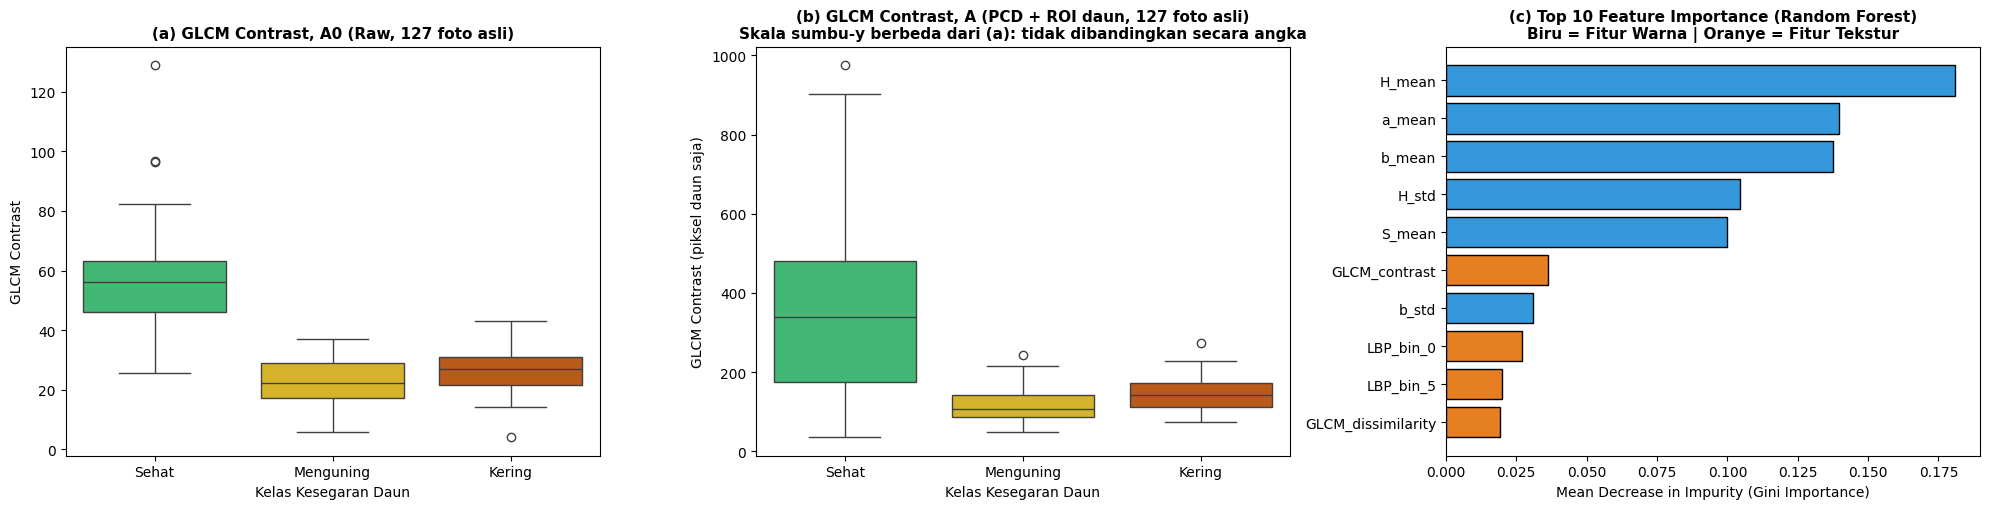

In [55]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

try:
    from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
except ImportError:
    from skimage.feature import greycomatrix as graycomatrix, greycoprops as graycoprops, local_binary_pattern

# Baca dataset_master_p2.csv v2 dari Sel 10 (folder v2; v1 tidak dipakai lagi)
OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2'
csv_master_path = os.path.join(OUT_BASE, 'dataset_master_p2.csv')
df_master_p2 = pd.read_csv(csv_master_path)
assert 'gamma_used' in df_master_p2.columns, "CSV ini bukan v2 (kolom gamma_used tidak ada). Periksa OUT_BASE."
print(f"Dataset v2 dibaca: {df_master_p2.shape[0]} baris dari {csv_master_path}")

COLOR_COLS = [
    'H_mean', 'H_std', 'S_mean', 'S_std', 'V_mean', 'V_std',
    'L_mean', 'L_std', 'a_mean', 'a_std', 'b_mean', 'b_std'
]
GLCM_PROPS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
GLCM_COLS = [f'GLCM_{p}' for p in GLCM_PROPS]
LBP_COLS = [f'LBP_bin_{i}' for i in range(10)]
ALL_FEATURE_COLS = COLOR_COLS + GLCM_COLS + LBP_COLS

def extract_handcrafted_features(img_bgr, mask=None, use_mask=True):
    """Mengekstrak 12 fitur warna (HSV+LAB), 6 fitur GLCM, dan 10 bin histogram LBP uniform."""
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    if use_mask and mask is not None and np.sum(mask > 0) > 50:
        valid = (mask > 0)
    else:
        valid = np.ones(gray.shape, dtype=bool)

    # 1. Ekstraksi 12 Fitur Statistik Warna (Mean & Std HSV + CIE-LAB)
    feats = {}
    for idx, ch_name in enumerate(['H', 'S', 'V']):
        vals = hsv[:, :, idx][valid]
        feats[f'{ch_name}_mean'] = float(np.mean(vals))
        feats[f'{ch_name}_std']  = float(np.std(vals))

    for idx, ch_name in enumerate(['L', 'a', 'b']):
        vals = lab[:, :, idx][valid]
        feats[f'{ch_name}_mean'] = float(np.mean(vals))
        feats[f'{ch_name}_std']  = float(np.std(vals))

    # 2. Ekstraksi 6 Fitur Tekstur Spasial GLCM (Jarak d=[1,2], 4 Sudut Arah)
    if use_mask and mask is not None and np.sum(mask > 0) > 50:
        # Geser intensitas piksel daun ke [1..255] agar nilai 0 khusus mewakili background hitam
        gray_glcm = np.where(valid, np.clip(gray, 1, 255), 0).astype(np.uint8)
        glcm = graycomatrix(
            gray_glcm, distances=[1, 2],
            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
            levels=256, symmetric=True, normed=False
        )
        # Buang baris 0 dan kolom 0 (transisi background) lalu normalisasi matriks
        glcm[0, :, :, :] = 0
        glcm[:, 0, :, :] = 0
        glcm_sum = np.sum(glcm, axis=(0, 1), keepdims=True)
        glcm_norm = np.divide(glcm.astype(np.float64), glcm_sum, out=np.zeros_like(glcm, dtype=np.float64), where=glcm_sum > 0)
    else:
        glcm_norm = graycomatrix(
            gray, distances=[1, 2],
            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
            levels=256, symmetric=True, normed=True
        )

    for prop in GLCM_PROPS:
        feats[f'GLCM_{prop}'] = float(np.mean(graycoprops(glcm_norm, prop)))

    # 3. Ekstraksi 10 Fitur Histogram Tekstur Lokal LBP (P=8, R=1, method='uniform')
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_vals = lbp[valid]
    hist, _ = np.histogram(lbp_vals, bins=np.arange(0, 11), density=True)
    for i in range(10):
        feats[f'LBP_bin_{i}'] = float(hist[i])

    return feats

records_A0, records_A = [], []

print("Mengekstrak 28 fitur (Warna + GLCM + LBP) pada 619 citra untuk Skenario A0 (Raw) & A (PCD)...")
for idx, row in tqdm(df_master_p2.iterrows(), total=len(df_master_p2)):
    meta = {
        'sample_id': row['sample_id'],
        'parent_id': row['parent_id'],
        'original_filename': row['original_filename'],
        'label': row['label'],
        'sesi': row['sesi'],
        'fold': row['fold'],
        'is_augmented': row['is_augmented'],
        'aug_type': row['aug_type']
    }

    img_a0 = cv2.imread(row['path_A0_raw'])
    img_c2 = cv2.imread(row['path_C2_masked'])
    msk_c2 = cv2.imread(row['path_mask'], cv2.IMREAD_GRAYSCALE)

    # Skenario A0: fitur dari gambar mentah utuh (tanpa PCD, tanpa mask; latar kertas ikut terhitung)
    f_a0 = extract_handcrafted_features(img_a0, mask=None, use_mask=False)
    records_A0.append({**meta, **f_a0})

    # Skenario A: fitur dari piksel daun (mask > 0) pada citra hasil PCD lengkap (C2)
    f_a = extract_handcrafted_features(img_c2, mask=msk_c2, use_mask=True)
    records_A.append({**meta, **f_a})

df_feat_A0 = pd.DataFrame(records_A0)
df_feat_A  = pd.DataFrame(records_A)

path_csv_a0 = os.path.join(OUT_BASE, 'features_A0_raw_p2.csv')
path_csv_a  = os.path.join(OUT_BASE, 'features_A_pcd_p2.csv')
df_feat_A0.to_csv(path_csv_a0, index=False)
df_feat_A.to_csv(path_csv_a, index=False)

print(f"\nSukses! Dimensi Tabel Fitur: {df_feat_A.shape} (619 sampel x {len(ALL_FEATURE_COLS)} fitur + 8 kolom metadata)")
print(f"- File Fitur A0 (Raw) tersimpan di : {path_csv_a0}")
print(f"- File Fitur A  (PCD) tersimpan di : {path_csv_a}")

# ==============================================================================
# VISUALISASI: SEBARAN GLCM CONTRAST (A0 vs A) & FEATURE IMPORTANCE
# ==============================================================================
df_orig_A0 = df_feat_A0[df_feat_A0['is_augmented'] == 0].copy()
df_orig_A  = df_feat_A[df_feat_A['is_augmented'] == 0].copy()

# Feature Importance (deskriptif) dari Random Forest pada data skenario A
X_imp = StandardScaler().fit_transform(df_feat_A[ALL_FEATURE_COLS])
rf_imp = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf_imp.fit(X_imp, df_feat_A['label'])
imp_series = pd.Series(rf_imp.feature_importances_, index=ALL_FEATURE_COLS).sort_values(ascending=True)

palette_cls = {'Sehat': '#2ecc71', 'Menguning': '#f1c40f', 'Kering': '#d35400'}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))

sns.boxplot(data=df_orig_A0, x='label', y='GLCM_contrast', hue='label', order=['Sehat', 'Menguning', 'Kering'], palette=palette_cls, legend=False, ax=axes[0])
axes[0].set_title('(a) GLCM Contrast, A0 (Raw, 127 foto asli)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Kelas Kesegaran Daun')
axes[0].set_ylabel('GLCM Contrast')

sns.boxplot(data=df_orig_A, x='label', y='GLCM_contrast', hue='label', order=['Sehat', 'Menguning', 'Kering'], palette=palette_cls, legend=False, ax=axes[1])
axes[1].set_title('(b) GLCM Contrast, A (PCD + ROI daun, 127 foto asli)\nSkala sumbu-y berbeda dari (a): tidak dibandingkan secara angka', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Kelas Kesegaran Daun')
axes[1].set_ylabel('GLCM Contrast (piksel daun saja)')

top10_imp = imp_series.tail(10)
colors_bar = ['#e67e22' if ('GLCM' in c or 'LBP' in c) else '#3498db' for c in top10_imp.index]
axes[2].barh(top10_imp.index, top10_imp.values, color=colors_bar, edgecolor='black')
axes[2].set_title('(c) Top 10 Feature Importance (Random Forest)\nBiru = Fitur Warna | Oranye = Fitur Tekstur', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Mean Decrease in Impurity (Gini Importance)')

plt.tight_layout()
plt.savefig('P2_Slide9_Sebaran_GLCM_dan_Feature_Importance.png', dpi=300)
plt.show()

### Analisis Keluaran Sel 11 (Separabilitas Fitur & Feature Importance)
**Cara membaca:** panel (a) dan (b) menampilkan sebaran `GLCM_contrast` pada 127 foto asli; panel (c) menampilkan 10 fitur terpenting menurut Random Forest (seluruh sampel, deskriptif, bukan uji signifikansi).

1. **Panel (a) dan (b) tidak dapat dibandingkan secara angka:** skala sumbu-y berbeda (≈0–130 vs ≈0–1000) karena skenario A dihitung hanya pada piksel daun pada ROI yang diperbesar ke 224×224, sedangkan A0 mencakup latar. Yang dapat dibandingkan hanya urutan antar kelas.
2. **Antar kelas:** pada A0, median Sehat ≈56, Menguning ≈22, dan Kering ≈27; kotak Menguning (≈17–29) dan Kering (≈21–31) tumpang tindih. Pada A, median Sehat ≈340, Menguning ≈107, dan Kering ≈143; kotak Menguning (≈88–142) dan Kering (≈112–173) masih sebagian tumpang tindih. Sehat memiliki kontras tertinggi dengan sebaran sangat lebar pada A (penyebabnya belum diselidiki). Tekstur memisahkan Sehat; untuk Menguning vs Kering hanya terlihat kecenderungan kecil.
3. **Panel (c):** lima fitur teratas semuanya warna (`H_mean` ≈0,18; `a_mean` ≈0,14; `b_mean` ≈0,14; `H_std` ≈0,10; `S_mean` ≈0,10). Fitur tekstur pertama, `GLCM_contrast`, berada di peringkat 6 (≈0,036); setiap fitur tekstur lain di 10 besar bernilai ≤0,03. Warna adalah prediktor dominan, dan hal ini selaras dengan Tabel 3 (tekstur tidak menambah F1 di atas warna).

## 12. Eksperimen Baseline ML Klasik (5-Fold CV): Komparasi PCD, Augmentasi, & Ablasi Fitur

**Tujuan:**
Mengevaluasi 3 algoritma ML klasik (**SVM Kernel RBF**, **Random Forest**, **KNN**) dengan **Stratified 5-Fold Cross-Validation** tanpa kebocoran parent:
- Pada setiap *fold* pengujian $k \in \{0, 1, 2, 3, 4\}$:
  - **Data Latih:** seluruh sampel pada `fold != k`.
  - **Data Uji:** hanya citra asli (`is_augmented == 0`) pada `fold == k` ($N_{test} = 127$ citra asli melintasi 5 *fold*), sehingga metrik tidak terinflasi oleh data sintetis.
- Split per foto belum memisahkan daun, sesi, atau ponsel. Karena itu hasil Bagian 12 dibaca bersama Bagian 14 (LOSO, CV berulang, McNemar).
- Menghasilkan **3 Tabel Hasil Eksperimen**:
  1. **Tabel 1 (A0 vs A):** membandingkan fitur dari citra mentah dengan fitur dari PCD + ROI daun.
  2. **Tabel 2 (Dampak Augmentasi):** pelatihan dengan *data asli saja ($N=127$)* vs *asli + sintetis ($N=619$)*; uji tetap pada foto asli. Kolom selisih dibaca dalam **poin Macro-F1**, bukan persen.
  3. **Tabel 3 (Ablasi Fitur):** *warna saja (12 fitur)* vs *tekstur GLCM+LBP saja (16 fitur)* vs *fusi (28 fitur)*.

In [56]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def get_ml_models():
    """Mendefinisikan 3 pipeline model ML klasik dengan normalisasi StandardScaler."""
    return {
        'SVM (RBF Kernel)': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(C=3.0, kernel='rbf', gamma='scale', class_weight='balanced', probability=True, random_state=42))
        ]),
        'Random Forest': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42))
        ]),
        'KNN (k=7, Distance)': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=7, weights='distance'))
        ])
    }

def evaluate_5fold_anti_leakage(df_features, feature_cols, use_augmented_train=True):
    """
    Evaluasi 5-Fold CV: Test Fold HANYA berisi foto asli (is_augmented == 0);
    Train Fold berisi foto asli + sintetis (use_augmented_train=True) atau foto asli saja (False).
    """
    models = get_ml_models()
    summary_rows = []
    oof_predictions = {}

    for model_name, pipe in models.items():
        fold_accs, fold_precs, fold_recs, fold_f1s = [], [], [], []
        y_true_all, y_pred_all, sample_ids_all = [], [], []

        for k in range(5):
            if use_augmented_train:
                train_df = df_features[df_features['fold'] != k]
            else:
                train_df = df_features[(df_features['fold'] != k) & (df_features['is_augmented'] == 0)]

            # KRITIS: data uji WAJIB murni citra asli
            test_df = df_features[(df_features['fold'] == k) & (df_features['is_augmented'] == 0)]
            assert set(train_df['parent_id']).isdisjoint(set(test_df['parent_id'])), 'KEBOCORAN parent_id'

            X_train, y_train = train_df[feature_cols].values, train_df['label'].values
            X_test,  y_test  = test_df[feature_cols].values,  test_df['label'].values

            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)

            fold_accs.append(accuracy_score(y_test, y_pred) * 100)
            fold_precs.append(precision_score(y_test, y_pred, average='macro', zero_division=0) * 100)
            fold_recs.append(recall_score(y_test, y_pred, average='macro', zero_division=0) * 100)
            fold_f1s.append(f1_score(y_test, y_pred, average='macro', zero_division=0) * 100)

            y_true_all.extend(y_test)
            y_pred_all.extend(y_pred)
            sample_ids_all.extend(test_df['sample_id'].values)

        oof_predictions[model_name] = pd.DataFrame({
            'sample_id': sample_ids_all, 'y_true': y_true_all, 'y_pred': y_pred_all
        })

        summary_rows.append({
            'Model ML Klasik': model_name,
            'Accuracy (%)': f"{np.mean(fold_accs):.2f} ± {np.std(fold_accs):.2f}",
            'Macro-Precision (%)': f"{np.mean(fold_precs):.2f} ± {np.std(fold_precs):.2f}",
            'Macro-Recall (%)': f"{np.mean(fold_recs):.2f} ± {np.std(fold_recs):.2f}",
            'Macro-F1 (%)': f"{np.mean(fold_f1s):.2f} ± {np.std(fold_f1s):.2f}",
            '_f1_mean': np.mean(fold_f1s),
            '_acc_mean': np.mean(fold_accs)
        })

    return pd.DataFrame(summary_rows), oof_predictions

# 1. TABEL 1: A0 (CITRA MENTAH) VS A (PCD + ROI DAUN)
df_res_A0, oof_A0 = evaluate_5fold_anti_leakage(df_feat_A0, ALL_FEATURE_COLS, use_augmented_train=True)
df_res_A,  oof_A  = evaluate_5fold_anti_leakage(df_feat_A,  ALL_FEATURE_COLS, use_augmented_train=True)

df_res_A0['Skenario'] = 'A0: Citra mentah + Fitur + ML'
df_res_A['Skenario']  = 'A: PCD + ROI daun (C2) + Fitur + ML'
df_table1 = pd.concat([df_res_A0, df_res_A], ignore_index=True)[
    ['Skenario', 'Model ML Klasik', 'Accuracy (%)', 'Macro-Precision (%)', 'Macro-Recall (%)', 'Macro-F1 (%)']
]

print("=" * 90)
print("TABEL 1: A0 (CITRA MENTAH) VS A (PCD + ROI DAUN), 5-fold acak, uji hanya foto asli")
print("=" * 90)
print(df_table1.to_string(index=False))

# 2. TABEL 2: DAMPAK AUGMENTASI (latih: asli saja N=127 vs asli+sintetis N=619; uji: foto asli)
df_res_no_aug, _ = evaluate_5fold_anti_leakage(df_feat_A, ALL_FEATURE_COLS, use_augmented_train=False)
df_table2 = pd.DataFrame({
    'Model ML Klasik': df_res_A['Model ML Klasik'],
    'Macro-F1 latih asli saja (N=127)': df_res_no_aug['Macro-F1 (%)'],
    'Macro-F1 latih asli+sintetis (N=619)': df_res_A['Macro-F1 (%)'],
    'Selisih Macro-F1 (poin)': [f"{a - b:+.2f}" for a, b in zip(df_res_A['_f1_mean'], df_res_no_aug['_f1_mean'])]
})

print("\n" + "=" * 90)
print("TABEL 2: DAMPAK AUGMENTASI PADA SKENARIO A (selisih dalam POIN Macro-F1, bukan persen)")
print("=" * 90)
print(df_table2.to_string(index=False))

# 3. TABEL 3: ABLASI FITUR (warna vs tekstur vs gabungan)
df_abl_color, _   = evaluate_5fold_anti_leakage(df_feat_A, COLOR_COLS, use_augmented_train=True)
df_abl_texture, _ = evaluate_5fold_anti_leakage(df_feat_A, GLCM_COLS + LBP_COLS, use_augmented_train=True)

df_table3 = pd.DataFrame({
    'Model ML Klasik': df_res_A['Model ML Klasik'],
    'Warna saja (12 fitur HSV+LAB)': df_abl_color['Macro-F1 (%)'],
    'Tekstur saja (16 fitur GLCM+LBP)': df_abl_texture['Macro-F1 (%)'],
    'Fusi warna + tekstur (28 fitur)': df_res_A['Macro-F1 (%)'],
    'Selisih fusi - warna (poin)': [f"{full - col:+.2f}" for full, col in zip(df_res_A['_f1_mean'], df_abl_color['_f1_mean'])]
})

print("\n" + "=" * 90)
print("TABEL 3: ABLASI FITUR PADA SKENARIO A (selisih dalam POIN Macro-F1)")
print("=" * 90)
print(df_table3.to_string(index=False))

# Simpan tabel ke CSV (folder v2)
df_table1.to_csv(os.path.join(OUT_BASE, 'P2_Tabel1_Komparasi_A0_vs_A.csv'), index=False)
df_table2.to_csv(os.path.join(OUT_BASE, 'P2_Tabel2_Dampak_Augmentasi.csv'), index=False)
df_table3.to_csv(os.path.join(OUT_BASE, 'P2_Tabel3_Ablasi_Fitur.csv'), index=False)

TABEL 1: A0 (CITRA MENTAH) VS A (PCD + ROI DAUN), 5-fold acak, uji hanya foto asli
                           Skenario     Model ML Klasik Accuracy (%) Macro-Precision (%) Macro-Recall (%) Macro-F1 (%)
      A0: Citra mentah + Fitur + ML    SVM (RBF Kernel) 92.92 ± 6.23        94.42 ± 4.81     93.10 ± 5.97 92.73 ± 6.35
      A0: Citra mentah + Fitur + ML       Random Forest 92.92 ± 5.10        94.00 ± 4.18     93.10 ± 4.19 92.77 ± 4.97
      A0: Citra mentah + Fitur + ML KNN (k=7, Distance) 93.72 ± 5.79        94.40 ± 4.82     94.17 ± 4.95 93.70 ± 5.66
A: PCD + ROI daun (C2) + Fitur + ML    SVM (RBF Kernel) 88.98 ± 4.59        90.54 ± 4.15     88.79 ± 5.33 88.36 ± 5.34
A: PCD + ROI daun (C2) + Fitur + ML       Random Forest 91.35 ± 2.92        91.56 ± 3.27     91.36 ± 3.08 91.17 ± 3.06
A: PCD + ROI daun (C2) + Fitur + ML KNN (k=7, Distance) 80.34 ± 2.26        81.63 ± 3.43     81.06 ± 2.53 80.18 ± 2.14

TABEL 2: DAMPAK AUGMENTASI PADA SKENARIO A (selisih dalam POIN Macro-F1, bukan pers

### Analisis Keluaran Sel 12 (Tabel 1–3, 5-fold acak)
1. **Tabel 1 (A0 vs A):** Macro-F1 A0 = 92,7 / 92,8 / 93,7 dan A = 88,4 / 91,2 / 80,2 (SVM / RF / KNN). Pada 5-fold acak, fitur dari PCD + ROI **tidak lebih baik** dari fitur citra mentah; pada KNN A0 lebih baik secara signifikan (McNemar p = 0,001, Bagian 14). Keunggulan A0 pada evaluasi ini diduga berasal dari ciri latar/orientasi/perangkat yang berlaku di dalam satu sesi tetapi tidak antar sesi; dugaan ini diperiksa dengan LOSO (Bagian 14).
2. **Tabel 2 (augmentasi):** Macro-F1 tanpa augmentasi 90,5 / 92,5 / 86,4 dan dengan augmentasi 88,4 / 91,2 / 80,2, jadi selisih −2,2 / −1,3 / −6,2 poin dengan simpangan baku 2–6 poin. **Tidak ada bukti bahwa augmentasi menaikkan akurasi pada 5-fold acak**; sampel sintetis bukan sampel independen sehingga pengaruhnya pada KNN justru negatif. Efek pada LOSO dilaporkan di Bagian 14 (E9).
3. **Tabel 3 (ablasi):** warna saja 91,9 / 92,6 / 88,0; tekstur saja 76,4 / 73,6 / 70,2; fusi 88,4 / 91,2 / 80,2. Penambahan tekstur tidak meningkatkan F1 (selisih −3,6 / −1,4 / −7,8 poin). Fitur tekstur dihitung pada citra 224 px (mikro-tekstur hilang) dan menambah dimensi tanpa informasi tambahan pada sampel efektif 127.
4. **Catatan:** 5-fold per foto tidak memisahkan sesi/ponsel; seluruh angka bagian ini dibaca bersama Bagian 14.

## 13. Visualisasi Confusion Matrix $3 \times 3$ (A0 vs A) & Diagnosis Error Analysis

**Tujuan:**
1. Membandingkan **Confusion Matrix $3 \times 3$** (*out-of-fold* pada 127 citra asli) antara **A0 (citra mentah)** dan **A (PCD + ROI daun)** pada model terbaik, untuk melihat di kelas mana kesalahan prediksi terjadi dan apakah polanya berubah antara A0 dan A.
2. Menampilkan **contoh foto asli yang salah diklasifikasikan** beserta kemungkinan penyebabnya, sebagai bahan "analisis masalah yang ditemukan" (syarat Progress 2) dan landasan eksplorasi *pretrained deep learning* pada Progress 3.

Model ML Klasik terbaik pada Skenario A: Random Forest



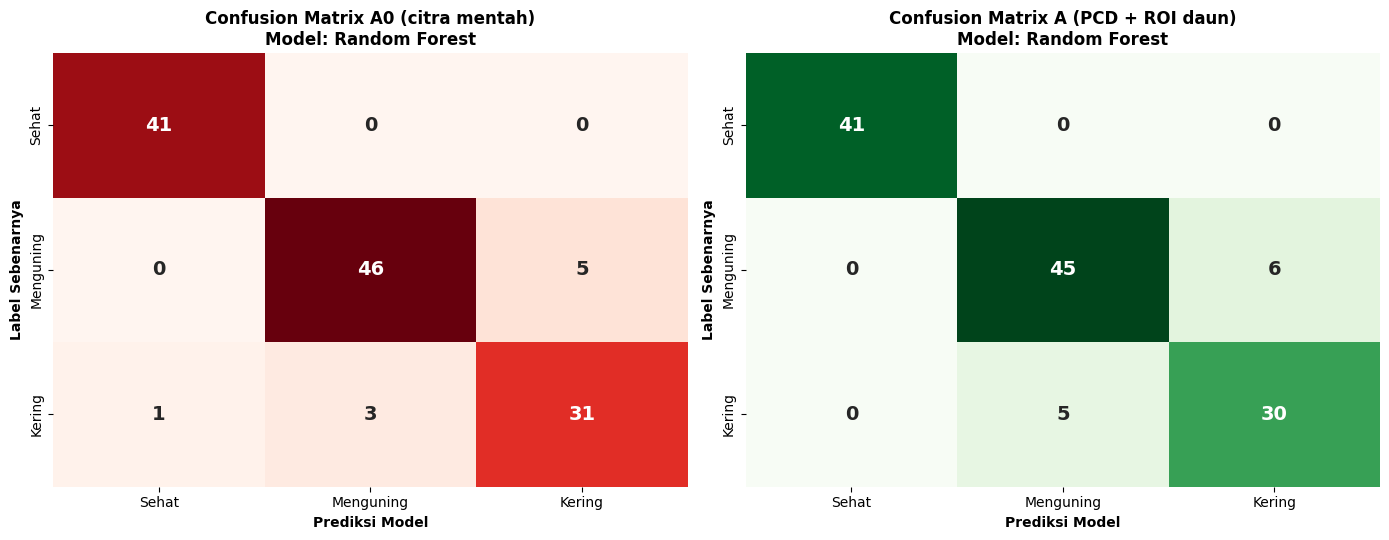

=== CLASSIFICATION REPORT PER KELAS (Random Forest - SKENARIO A) ===
              precision    recall  f1-score   support

       Sehat     1.0000    1.0000    1.0000        41
   Menguning     0.9000    0.8824    0.8911        51
      Kering     0.8333    0.8571    0.8451        35

    accuracy                         0.9134       127
   macro avg     0.9111    0.9132    0.9121       127
weighted avg     0.9139    0.9134    0.9136       127


A  (PCD + ROI): 11 dari 127 foto asli salah.
    sample_id       original_filename  sesi    y_true    y_pred
LEAF_057_orig IMG_20261022_154520.jpg     1 Menguning    Kering
LEAF_074_orig IMG_20261022_155435.jpg     1 Menguning    Kering
LEAF_115_orig IMG_20261022_155817.jpg     1    Kering Menguning
LEAF_058_orig IMG_20261022_154522.jpg     1 Menguning    Kering
LEAF_061_orig IMG_20261022_154553.jpg     1 Menguning    Kering
LEAF_073_orig IMG_20261022_155402.jpg     1 Menguning    Kering
LEAF_097_orig IMG_20261022_154642.jpg     1    Kering Me

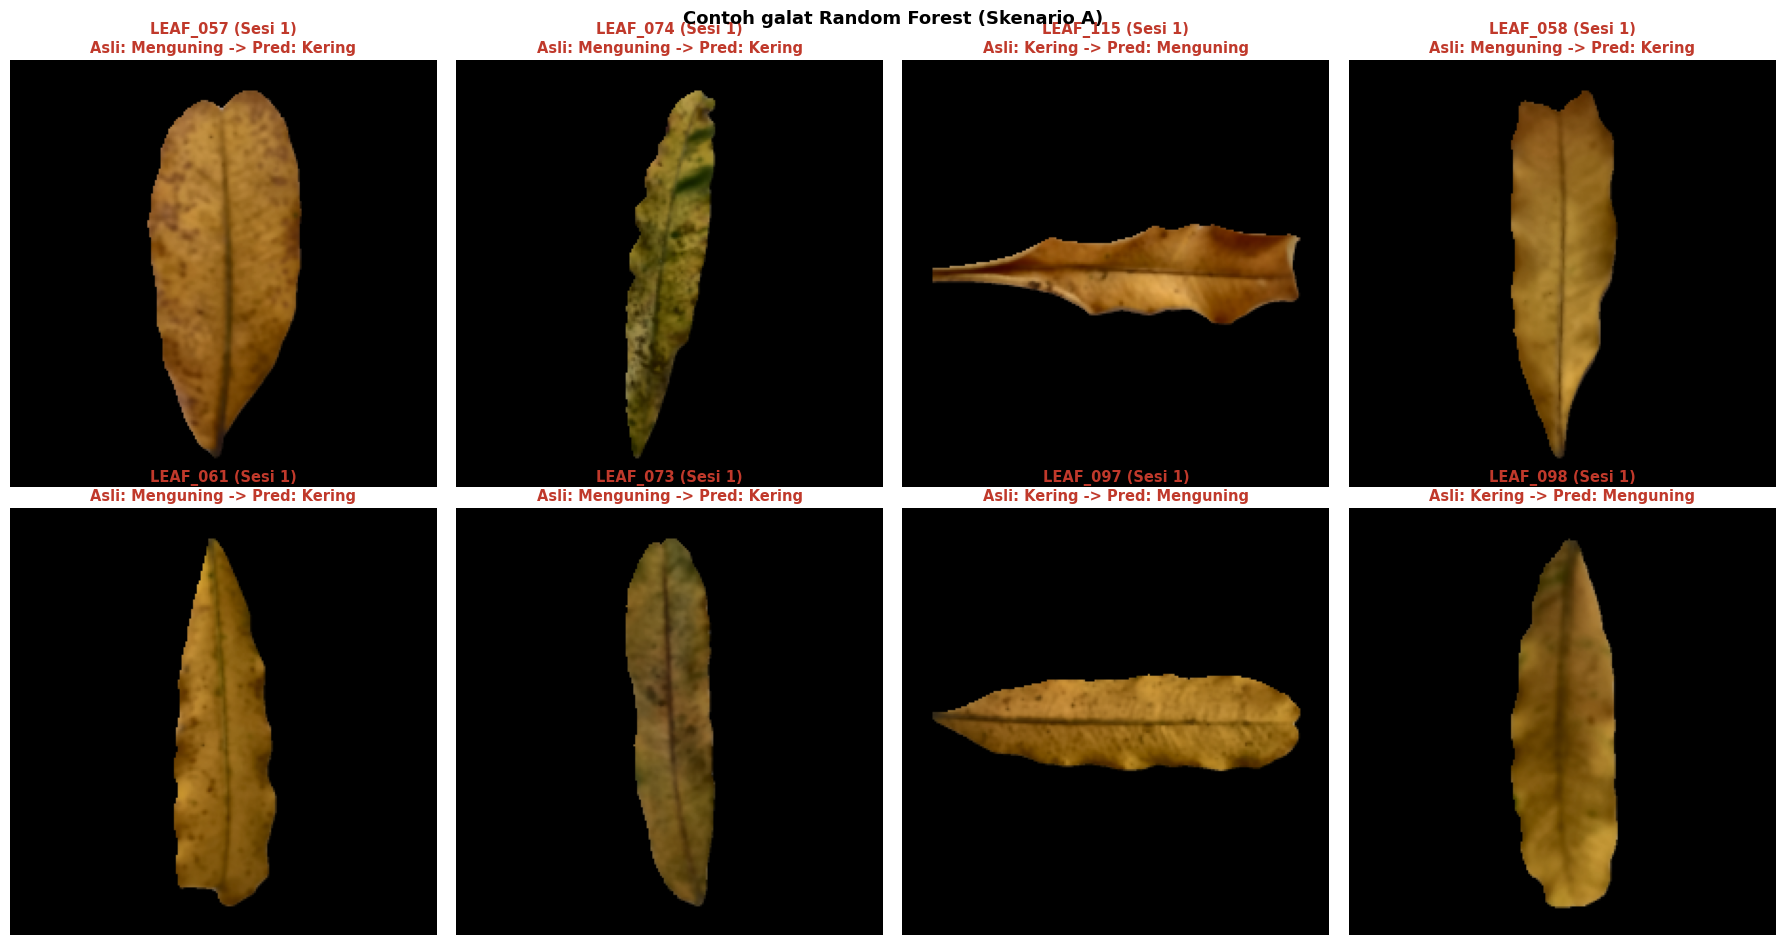

In [57]:
from sklearn.metrics import confusion_matrix, classification_report

# Model terbaik pada Skenario A (Macro-F1 rata-rata tertinggi)
best_model_name = df_res_A.sort_values(by='_f1_mean', ascending=False).iloc[0]['Model ML Klasik']
print(f"Model ML Klasik terbaik pada Skenario A: {best_model_name}\n")

labels_order = ['Sehat', 'Menguning', 'Kering']
oof_best_A0 = oof_A0[best_model_name]
oof_best_A  = oof_A[best_model_name]

cm_A0 = confusion_matrix(oof_best_A0['y_true'], oof_best_A0['y_pred'], labels=labels_order)
cm_A  = confusion_matrix(oof_best_A['y_true'],  oof_best_A['y_pred'],  labels=labels_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm_A0, annot=True, fmt='d', cmap='Reds', xticklabels=labels_order, yticklabels=labels_order, cbar=False, annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[0])
axes[0].set_title(f'Confusion Matrix A0 (citra mentah)\nModel: {best_model_name}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi Model', fontweight='bold'); axes[0].set_ylabel('Label Sebenarnya', fontweight='bold')
sns.heatmap(cm_A, annot=True, fmt='d', cmap='Greens', xticklabels=labels_order, yticklabels=labels_order, cbar=False, annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[1])
axes[1].set_title(f'Confusion Matrix A (PCD + ROI daun)\nModel: {best_model_name}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediksi Model', fontweight='bold'); axes[1].set_ylabel('Label Sebenarnya', fontweight='bold')
plt.tight_layout()
plt.savefig('P2_Confusion_Matrix_A0_vs_A.png', dpi=300)
plt.show()

print(f"=== CLASSIFICATION REPORT PER KELAS ({best_model_name} - SKENARIO A) ===")
print(classification_report(oof_best_A['y_true'], oof_best_A['y_pred'], labels=labels_order, digits=4))

# ----------------------------------------------------------------------------
# ANALISIS GALAT: SEMUA sampel asli yang salah (tidak dipotong)
# ----------------------------------------------------------------------------
meta_cols = ['sample_id', 'parent_id', 'original_filename', 'sesi', 'path_C1_nomask', 'path_C2_masked']

def error_table(oof_df):
    e = oof_df[oof_df['y_true'] != oof_df['y_pred']].copy()
    return e.merge(df_master_p2[meta_cols], on='sample_id', how='left')

df_errors   = error_table(oof_best_A)
df_errors_0 = error_table(oof_best_A0)

print(f"\nA  (PCD + ROI): {len(df_errors)} dari 127 foto asli salah.")
print(df_errors[['sample_id', 'original_filename', 'sesi', 'y_true', 'y_pred']].to_string(index=False))
print("\nRingkasan galat A  per (sesi, label benar -> prediksi):")
print(df_errors.groupby(['sesi', 'y_true', 'y_pred']).size().to_string())

print(f"\nA0 (citra mentah): {len(df_errors_0)} dari 127 foto asli salah.")
print(df_errors_0[['sample_id', 'original_filename', 'sesi', 'y_true', 'y_pred']].to_string(index=False))
print("\nRingkasan galat A0 per (sesi, label benar -> prediksi):")
print(df_errors_0.groupby(['sesi', 'y_true', 'y_pred']).size().to_string())

# Galat A yang juga salah pada A0 (galat yang konsisten di kedua skenario)
both = set(df_errors['parent_id']) & set(df_errors_0['parent_id'])
print(f"\nGalat yang sama pada A dan A0: {len(both)} foto -> {sorted(both)}")

# Tampilkan sampai 8 contoh galat A (ROI C2)
n_show = min(8, len(df_errors))
if n_show > 0:
    cols = 4
    rows_ = int(np.ceil(n_show / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(4.5 * cols, 4.8 * rows_))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis('off')
    for idx_err, (_, err_row) in enumerate(df_errors.iloc[:n_show].iterrows()):
        img_err = cv2.imread(err_row['path_C2_masked'])
        axes[idx_err].imshow(cv2.cvtColor(img_err, cv2.COLOR_BGR2RGB))
        axes[idx_err].set_title(
            f"{err_row['parent_id']} (Sesi {err_row['sesi']})\nAsli: {err_row['y_true']} -> Pred: {err_row['y_pred']}",
            fontsize=10.5, fontweight='bold', color='#c0392b')
    plt.suptitle(f"Contoh galat {best_model_name} (Skenario A)", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('P2_Error_Analysis_Samples.png', dpi=300, bbox_inches='tight')
    plt.show()

### Analisis Keluaran Sel 13 (Analisis Galat)
1. **Galat terkonsentrasi di Menguning ↔ Kering.** Random Forest (skenario A) salah pada 11 dari 127 foto: 6 Menguning→Kering dan 5 Kering→Menguning; Sehat benar 41/41. Pada A0 terdapat 9 galat (5 Menguning→Kering, 3 Kering→Menguning, 1 Kering→Sehat). Jadi pada 5-fold acak PCD + ROI tidak mengurangi galat (11 vs 9; McNemar p = 0,754 untuk RF).
2. **Sesi asal galat:** seluruh **11 dari 11 galat** (100%) pada Skenario A berasal dari **Sesi 1** (`6 Menguning→Kering` dan `5 Kering→Menguning`). Batas Menguning/Kering pada Sesi 1 ditetapkan secara visual. Nilai Cohen's κ = 0,882 hanya menunjukkan konsistensi pelabelan ulang oleh satu orang, bukan kesepakatan antar-anotator, dan 10 foto di Sesi 1 telah dipindahkan dari `Kering` ke `Menguning` saat audit label. Kemungkinan sebagian galat adalah *noise* label pada zona transisi tersebut (pencocokan langsung per `parent_id` tidak dapat dilakukan secara otomatis karena pemindahan 10 foto dilakukan pada folder Drive sebelum pembuatan `manifest.csv`).
3. **Hipotesis (belum diuji):** fitur global merata-ratakan seluruh daun sehingga daun yang menguning sebagian dengan bercak sulit dibedakan dari kelas lain. Hipotesis ini diuji pada Progress 3 dengan model konvolusional (YOLO-cls, MobileNetV2/V3, EfficientNet-B0) pada protokol yang sama.
4. **Catatan kasus:** LEAF_074 memiliki bercak hijau pada daun kuning (kasus batas). Contoh Sehat pada Sel 8 memiliki tepi kuning-krem (pola menyerupai variegata), tetapi Sehat tidak pernah salah, sehingga pola tersebut bukan sumber galat. Jumlah foto Sehat bertepi kuning belum dihitung dan spesies daun belum teridentifikasi; tidak ada dasar untuk klaim "beberapa spesies".

## 14. Evaluasi Lintas Sesi (LOSO), CV Berulang, Uji McNemar, dan Pemisahan Efek PCD vs Topeng

**Mengapa:** split per foto tidak memisahkan daun, pohon, atau sesi, dan pada Sesi 1 satu kelas = satu ponsel. Angka 5-fold acak bisa terlalu optimistis. Pemeriksaan:
- **E1 LOSO:** latih Sesi 1 → uji Sesi 2, dan sebaliknya (uji hanya foto asli).
- **E2 CV berulang:** 5-fold × 4 pengacakan → 20 nilai Macro-F1 (rata-rata ± SD).
- **E3 McNemar eksak:** apakah A0 (mentah) dan A (PCD + ROI) berbeda pada 127 foto asli?
- **E4 Ablasi berpasangan:** warna vs fusi pada 20 lipatan yang sama.
- **E8 Pemisahan efek:** A0 (mentah) vs C1 (PCD tanpa topeng) vs A (PCD + topeng) pada LOSO, untuk menentukan apakah keunggulan A berasal dari PCD atau dari topeng ROI. Tabel silang orientasi foto × kelas × sesi memeriksa jalan pintas non-daun.
- **E9 Dampak augmentasi pada LOSO:** latih asli saja vs asli + sintetis, uji pada foto asli sesi lain.

**Aturan:** uji hanya pada `is_augmented == 0`; `parent_id` tidak boleh ada di kedua sisi (assert).

In [58]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score
from scipy.stats import binomtest

def add_repeated_folds(df, seeds=(0, 1, 2)):
    """Fold tambahan per foto ASLI (stratified); anak augmentasi mewarisi fold induknya."""
    df = df.copy()
    orig = df[df.is_augmented == 0][['parent_id', 'label']].drop_duplicates().reset_index(drop=True)
    for s in seeds:
        fmap = {}
        for k, (_, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=s).split(orig, orig.label)):
            for pid in orig.loc[va, 'parent_id']: fmap[pid] = k
        df[f'fold_s{s}'] = df.parent_id.map(fmap)
    return df

def cv_repeated(df, cols, pipe, fold_cols=('fold', 'fold_s0', 'fold_s1', 'fold_s2'), use_aug=True):
    f1s, oof = [], {}
    for fc in fold_cols:
        pred = pd.Series(index=df[df.is_augmented == 0].sample_id, dtype=object)
        for k in range(5):
            tr = df[df[fc] != k]
            if not use_aug: tr = tr[tr.is_augmented == 0]
            te = df[(df[fc] == k) & (df.is_augmented == 0)]
            assert set(tr.parent_id).isdisjoint(te.parent_id), 'KEBOCORAN parent_id'
            m = clone(pipe).fit(tr[cols].values, tr.label.values)
            p = m.predict(te[cols].values)
            f1s.append(f1_score(te.label, p, average='macro') * 100)
            pred.loc[te.sample_id.values] = p
        oof[fc] = pred
    return np.array(f1s), oof

def loso(df, cols, pipe, train_sesi):
    tr = df[df.sesi == train_sesi]
    te = df[(df.sesi != train_sesi) & (df.is_augmented == 0)]
    assert set(tr.parent_id).isdisjoint(te.parent_id), 'KEBOCORAN parent_id'
    m = clone(pipe).fit(tr[cols].values, tr.label.values); p = m.predict(te[cols].values)
    maj = te.label.value_counts(normalize=True).max() * 100
    return f1_score(te.label, p, average='macro') * 100, accuracy_score(te.label, p) * 100, maj

def mcnemar_exact(y, pa, pb):
    a_ok, b_ok = (np.asarray(pa) == np.asarray(y)), (np.asarray(pb) == np.asarray(y))
    n01, n10 = int((~a_ok & b_ok).sum()), int((a_ok & ~b_ok).sum())
    p = 1.0 if n01 + n10 == 0 else binomtest(min(n01, n10), n01 + n10, 0.5).pvalue
    return n01, n10, p

dA0, dA = add_repeated_folds(df_feat_A0), add_repeated_folds(df_feat_A)
models = get_ml_models()
rows_cv, rows_loso, rows_mc, rows_abl = [], [], [], []
oofs = {}

for mname, pipe in models.items():
    for scen, d in (('A0 (mentah)', dA0), ('A (PCD+ROI)', dA)):
        f, oof = cv_repeated(d, ALL_FEATURE_COLS, pipe); oofs[(mname, scen)] = oof
        rows_cv.append(dict(Model=mname, Skenario=scen, **{'Macro-F1 20 lipatan': f"{f.mean():.1f} ± {f.std():.1f}"}))
        for tr_s in (1, 2):
            f1_, acc_, maj_ = loso(d, ALL_FEATURE_COLS, pipe, tr_s)
            rows_loso.append(dict(Model=mname, Skenario=scen, Latih=f'Sesi {tr_s}', Uji=f'Sesi {3 - tr_s}',
                                  **{'Macro-F1': round(f1_, 1), 'Akurasi': round(acc_, 1), 'Baseline mayoritas': round(maj_, 1)}))
    # E3: McNemar A0 vs A pada prediksi out-of-fold (pengacakan 'fold' asli)
    yv = dA[dA.is_augmented == 0].set_index('sample_id').loc[oofs[(mname, 'A0 (mentah)')]['fold'].index, 'label']
    n01, n10, p = mcnemar_exact(yv.values, oofs[(mname, 'A0 (mentah)')]['fold'].values, oofs[(mname, 'A (PCD+ROI)')]['fold'].values)
    rows_mc.append(dict(Model=mname, **{'A0 benar & A salah': n10, 'A0 salah & A benar': n01, 'p (McNemar eksak)': round(p, 3)}))
    # E4: warna saja vs fusi, 20 lipatan yang sama (skenario A)
    f_col, _ = cv_repeated(dA, COLOR_COLS, pipe); f_all, _ = cv_repeated(dA, ALL_FEATURE_COLS, pipe)
    dlt = f_all - f_col
    rows_abl.append(dict(Model=mname, **{'F1 warna': f"{f_col.mean():.1f}", 'F1 fusi': f"{f_all.mean():.1f}",
                                         'Δ (fusi−warna) rata-rata ± SD': f"{dlt.mean():+.1f} ± {dlt.std():.1f}",
                                         'Fusi ≥ warna (dari 20)': int((dlt >= 0).sum())}))

df_e2, df_e1, df_e3, df_e4 = map(pd.DataFrame, (rows_cv, rows_loso, rows_mc, rows_abl))
print("E2  Macro-F1, 5-fold × 4 pengacakan (20 nilai)"); print(df_e2.to_string(index=False))
print("\nE1  LOSO (uji hanya foto asli sesi lain)");       print(df_e1.to_string(index=False))
print("\nE3  McNemar eksak A0 vs A");                       print(df_e3.to_string(index=False))
print("\nE4  Ablasi berpasangan warna vs fusi (skenario A)"); print(df_e4.to_string(index=False))
for nm, d_ in (('E1_LOSO', df_e1), ('E2_CV_berulang', df_e2), ('E3_McNemar', df_e3), ('E4_Ablasi_berpasangan', df_e4)):
    d_.to_csv(os.path.join(OUT_BASE, f'P2_{nm}.csv'), index=False)

E2  Macro-F1, 5-fold × 4 pengacakan (20 nilai)
              Model    Skenario Macro-F1 20 lipatan
   SVM (RBF Kernel) A0 (mentah)          93.3 ± 4.9
   SVM (RBF Kernel) A (PCD+ROI)          91.2 ± 5.9
      Random Forest A0 (mentah)          91.1 ± 4.9
      Random Forest A (PCD+ROI)          91.1 ± 5.8
KNN (k=7, Distance) A0 (mentah)          92.0 ± 6.3
KNN (k=7, Distance) A (PCD+ROI)          82.8 ± 5.5

E1  LOSO (uji hanya foto asli sesi lain)
              Model    Skenario  Latih    Uji  Macro-F1  Akurasi  Baseline mayoritas
   SVM (RBF Kernel) A0 (mentah) Sesi 1 Sesi 2      34.7     42.9                45.2
   SVM (RBF Kernel) A0 (mentah) Sesi 2 Sesi 1      22.5     23.5                47.1
   SVM (RBF Kernel) A (PCD+ROI) Sesi 1 Sesi 2      94.2     95.2                45.2
   SVM (RBF Kernel) A (PCD+ROI) Sesi 2 Sesi 1      73.1     71.8                47.1
      Random Forest A0 (mentah) Sesi 1 Sesi 2      16.3     23.8                45.2
      Random Forest A0 (mentah) Sesi 

In [59]:
import re
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score
from scipy.stats import binomtest
from tqdm import tqdm

def add_repeated_folds(df, seeds=(0, 1, 2)):
    """Fold tambahan per foto ASLI (stratified); anak augmentasi mewarisi fold induknya."""
    df = df.copy()
    orig = df[df.is_augmented == 0][['parent_id', 'label']].drop_duplicates().reset_index(drop=True)
    for s in seeds:
        fmap = {}
        for k, (_, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=s).split(orig, orig.label)):
            for pid in orig.loc[va, 'parent_id']: fmap[pid] = k
        df[f'fold_s{s}'] = df.parent_id.map(fmap)
    return df

def cv_repeated(df, cols, pipe, fold_cols=('fold', 'fold_s0', 'fold_s1', 'fold_s2'), use_aug=True):
    f1s, oof = [], {}
    for fc in fold_cols:
        pred = pd.Series(index=df[df.is_augmented == 0].sample_id, dtype=object)
        for k in range(5):
            tr = df[df[fc] != k]
            if not use_aug: tr = tr[tr.is_augmented == 0]
            te = df[(df[fc] == k) & (df.is_augmented == 0)]
            assert set(tr.parent_id).isdisjoint(te.parent_id), 'KEBOCORAN parent_id'
            m = clone(pipe).fit(tr[cols].values, tr.label.values)
            p = m.predict(te[cols].values)
            f1s.append(f1_score(te.label, p, average='macro') * 100)
            pred.loc[te.sample_id.values] = p
        oof[fc] = pred
    return np.array(f1s), oof

def loso(df, cols, pipe, train_sesi):
    tr = df[df.sesi == train_sesi]
    te = df[(df.sesi != train_sesi) & (df.is_augmented == 0)]
    assert set(tr.parent_id).isdisjoint(te.parent_id), 'KEBOCORAN parent_id'
    m = clone(pipe).fit(tr[cols].values, tr.label.values); p = m.predict(te[cols].values)
    maj = te.label.value_counts(normalize=True).max() * 100
    return f1_score(te.label, p, average='macro') * 100, accuracy_score(te.label, p) * 100, maj

def mcnemar_exact(y, pa, pb):
    a_ok, b_ok = (np.asarray(pa) == np.asarray(y)), (np.asarray(pb) == np.asarray(y))
    n01, n10 = int((~a_ok & b_ok).sum()), int((a_ok & ~b_ok).sum())
    p = 1.0 if n01 + n10 == 0 else binomtest(min(n01, n10), n01 + n10, 0.5).pvalue
    return n01, n10, p

# ============================ E1–E4 ============================
dA0, dA = add_repeated_folds(df_feat_A0), add_repeated_folds(df_feat_A)
models = get_ml_models()
rows_cv, rows_loso, rows_mc, rows_abl = [], [], [], []
oofs = {}

for mname, pipe in models.items():
    for scen, d in (('A0 (mentah)', dA0), ('A (PCD+ROI)', dA)):
        f, oof = cv_repeated(d, ALL_FEATURE_COLS, pipe); oofs[(mname, scen)] = oof
        rows_cv.append(dict(Model=mname, Skenario=scen, **{'Macro-F1 20 lipatan': f"{f.mean():.1f} ± {f.std():.1f}"}))
        for tr_s in (1, 2):
            f1_, acc_, maj_ = loso(d, ALL_FEATURE_COLS, pipe, tr_s)
            rows_loso.append(dict(Model=mname, Skenario=scen, Latih=f'Sesi {tr_s}', Uji=f'Sesi {3 - tr_s}',
                                  **{'Macro-F1': round(f1_, 1), 'Akurasi': round(acc_, 1), 'Baseline mayoritas': round(maj_, 1)}))
    # E3: McNemar A0 vs A pada prediksi out-of-fold (pengacakan 'fold' asli)
    yv = dA[dA.is_augmented == 0].set_index('sample_id').loc[oofs[(mname, 'A0 (mentah)')]['fold'].index, 'label']
    n01, n10, p = mcnemar_exact(yv.values, oofs[(mname, 'A0 (mentah)')]['fold'].values, oofs[(mname, 'A (PCD+ROI)')]['fold'].values)
    rows_mc.append(dict(Model=mname, **{'A0 benar & A salah': n10, 'A0 salah & A benar': n01, 'p (McNemar eksak)': round(p, 3)}))
    # E4: warna saja vs fusi, 20 lipatan yang sama (skenario A)
    f_col, _ = cv_repeated(dA, COLOR_COLS, pipe); f_all, _ = cv_repeated(dA, ALL_FEATURE_COLS, pipe)
    dlt = f_all - f_col
    rows_abl.append(dict(Model=mname, **{'F1 warna': f"{f_col.mean():.1f}", 'F1 fusi': f"{f_all.mean():.1f}",
                                         'Δ (fusi−warna) rata-rata ± SD': f"{dlt.mean():+.1f} ± {dlt.std():.1f}",
                                         'Fusi ≥ warna (dari 20)': int((dlt >= 0).sum())}))

df_e2, df_e1, df_e3, df_e4 = map(pd.DataFrame, (rows_cv, rows_loso, rows_mc, rows_abl))
print("E2  Macro-F1, 5-fold × 4 pengacakan (20 nilai)"); print(df_e2.to_string(index=False))
print("\nE1  LOSO (uji hanya foto asli sesi lain)");       print(df_e1.to_string(index=False))
print("\nE3  McNemar eksak A0 vs A");                       print(df_e3.to_string(index=False))
print("\nE4  Ablasi berpasangan warna vs fusi (skenario A)"); print(df_e4.to_string(index=False))

E2  Macro-F1, 5-fold × 4 pengacakan (20 nilai)
              Model    Skenario Macro-F1 20 lipatan
   SVM (RBF Kernel) A0 (mentah)          93.3 ± 4.9
   SVM (RBF Kernel) A (PCD+ROI)          91.2 ± 5.9
      Random Forest A0 (mentah)          91.1 ± 4.9
      Random Forest A (PCD+ROI)          91.1 ± 5.8
KNN (k=7, Distance) A0 (mentah)          92.0 ± 6.3
KNN (k=7, Distance) A (PCD+ROI)          82.8 ± 5.5

E1  LOSO (uji hanya foto asli sesi lain)
              Model    Skenario  Latih    Uji  Macro-F1  Akurasi  Baseline mayoritas
   SVM (RBF Kernel) A0 (mentah) Sesi 1 Sesi 2      34.7     42.9                45.2
   SVM (RBF Kernel) A0 (mentah) Sesi 2 Sesi 1      22.5     23.5                47.1
   SVM (RBF Kernel) A (PCD+ROI) Sesi 1 Sesi 2      94.2     95.2                45.2
   SVM (RBF Kernel) A (PCD+ROI) Sesi 2 Sesi 1      73.1     71.8                47.1
      Random Forest A0 (mentah) Sesi 1 Sesi 2      16.3     23.8                45.2
      Random Forest A0 (mentah) Sesi 

In [60]:
# ============================ E8 ============================
# Memisahkan efek PCD dari efek topeng ROI pada LOSO:
#   A0 = mentah tanpa topeng | C1 = PCD tanpa topeng | A = PCD + topeng ROI
recs = []
for _, r in tqdm(df_master_p2.iterrows(), total=len(df_master_p2), desc="E8: fitur C1 (PCD tanpa topeng)"):
    f = extract_handcrafted_features(cv2.imread(r['path_C1_nomask']), mask=None, use_mask=False)
    recs.append({'sample_id': r['sample_id'], 'parent_id': r['parent_id'], 'label': r['label'], 'sesi': r['sesi'],
                 'fold': r['fold'], 'is_augmented': r['is_augmented'], **f})
dC1 = add_repeated_folds(pd.DataFrame(recs))

rows_e8 = []
for mname, pipe in models.items():
    for tr_s in (1, 2):
        f1_, acc_, maj_ = loso(dC1, ALL_FEATURE_COLS, pipe, tr_s)
        rows_e8.append(dict(Model=mname, Skenario='C1 (PCD tanpa topeng)', Latih=f'Sesi {tr_s}', Uji=f'Sesi {3 - tr_s}',
                            **{'Macro-F1': round(f1_, 1), 'Akurasi': round(acc_, 1), 'Baseline mayoritas': round(maj_, 1)}))
df_e8 = pd.DataFrame(rows_e8)

print("\nE8  LOSO, A0 (mentah) vs C1 (PCD tanpa topeng) vs A (PCD + topeng): Macro-F1")
df_loso_all = pd.concat([df_e1, df_e8], ignore_index=True)
print(df_loso_all.pivot_table(index=['Model', 'Latih'], columns='Skenario', values='Macro-F1').round(1).to_string())
print("\nE8  rincian C1 (PCD tanpa topeng)"); print(df_e8.to_string(index=False))

# Orientasi foto asli (dihitung dari gambar, mengikuti EXIF seperti pipeline) vs kelas vs sesi
ori = {}
for _, r in df_clean.iterrows():
    h_, w_ = cv2.imread(r['filepath']).shape[:2]
    ori[r['id_daun']] = 'potret' if h_ > w_ else 'lanskap'
d0 = df_master_p2[df_master_p2.is_augmented == 0].copy()
d0['orientasi'] = d0['parent_id'].map(ori)
print("\nOrientasi foto asli per sesi dan kelas (kandidat jalan pintas untuk A0):")
print(pd.crosstab([d0.sesi, d0.label], d0.orientasi))

for nm, d_ in (('E1_LOSO', df_e1), ('E2_CV_berulang', df_e2), ('E3_McNemar', df_e3),
               ('E4_Ablasi_berpasangan', df_e4), ('E8_LOSO_C1', df_e8)):
    d_.to_csv(os.path.join(OUT_BASE, f'P2_{nm}.csv'), index=False)

E8: fitur C1 (PCD tanpa topeng): 100%|██████████| 619/619 [00:45<00:00, 13.61it/s]



E8  LOSO, A0 (mentah) vs C1 (PCD tanpa topeng) vs A (PCD + topeng): Macro-F1
Skenario                    A (PCD+ROI)  A0 (mentah)  C1 (PCD tanpa topeng)
Model               Latih                                                  
KNN (k=7, Distance) Sesi 1         91.3         16.3                   17.9
                    Sesi 2         62.9         22.8                   31.4
Random Forest       Sesi 1        100.0         16.3                   12.6
                    Sesi 2         83.7         15.9                   17.4
SVM (RBF Kernel)    Sesi 1         94.2         34.7                   16.7
                    Sesi 2         73.1         22.5                   19.3

E8  rincian C1 (PCD tanpa topeng)
              Model              Skenario  Latih    Uji  Macro-F1  Akurasi  Baseline mayoritas
   SVM (RBF Kernel) C1 (PCD tanpa topeng) Sesi 1 Sesi 2      16.7     23.8                45.2
   SVM (RBF Kernel) C1 (PCD tanpa topeng) Sesi 2 Sesi 1      19.3     20.0               

In [61]:
# ============================ E9: Dampak augmentasi pada LOSO ============================
# Latih: Sesi k (asli saja vs asli+sintetis). Uji: foto ASLI sesi lain. Skenario A (PCD + ROI).
rows_e9 = []
for mname, pipe in models.items():
    for tr_s in (1, 2):
        for use_aug in (False, True):
            tr = dA[dA.sesi == tr_s]
            if not use_aug:
                tr = tr[tr.is_augmented == 0]
            te = dA[(dA.sesi != tr_s) & (dA.is_augmented == 0)]
            assert set(tr.parent_id).isdisjoint(te.parent_id), 'KEBOCORAN parent_id'
            m = clone(pipe).fit(tr[ALL_FEATURE_COLS].values, tr.label.values)
            p = m.predict(te[ALL_FEATURE_COLS].values)
            rows_e9.append(dict(Model=mname, Latih=f'Sesi {tr_s}', Augmentasi='dengan' if use_aug else 'tanpa',
                                n_latih=len(tr),
                                **{'Macro-F1': round(f1_score(te.label, p, average='macro') * 100, 1),
                                   'Akurasi': round(accuracy_score(te.label, p) * 100, 1)}))
df_e9 = pd.DataFrame(rows_e9)
print("E9  LOSO skenario A: Macro-F1 tanpa vs dengan augmentasi")
print(df_e9.pivot_table(index=['Model', 'Latih'], columns='Augmentasi', values='Macro-F1').round(1).to_string())
print("\nRincian:"); print(df_e9.to_string(index=False))
df_e9.to_csv(os.path.join(OUT_BASE, 'P2_E9_Augmentasi_LOSO.csv'), index=False)

E9  LOSO skenario A: Macro-F1 tanpa vs dengan augmentasi
Augmentasi                  dengan  tanpa
Model               Latih                
KNN (k=7, Distance) Sesi 1    91.3   94.2
                    Sesi 2    62.9   56.5
Random Forest       Sesi 1   100.0  100.0
                    Sesi 2    83.7   78.9
SVM (RBF Kernel)    Sesi 1    94.2   87.9
                    Sesi 2    73.1   73.2

Rincian:
              Model  Latih Augmentasi  n_latih  Macro-F1  Akurasi
   SVM (RBF Kernel) Sesi 1      tanpa       85      87.9     88.1
   SVM (RBF Kernel) Sesi 1     dengan      408      94.2     95.2
   SVM (RBF Kernel) Sesi 2      tanpa       42      73.2     71.8
   SVM (RBF Kernel) Sesi 2     dengan      211      73.1     71.8
      Random Forest Sesi 1      tanpa       85     100.0    100.0
      Random Forest Sesi 1     dengan      408     100.0    100.0
      Random Forest Sesi 2      tanpa       42      78.9     77.6
      Random Forest Sesi 2     dengan      211      83.7     82.4
KNN

### Analisis Keluaran Sel 14
1. **LOSO vs 5-fold acak.** Pada A0 (citra mentah), Macro-F1 antar-sesi hanya 15,9–34,7 (akurasi 17,6–42,9%), jauh di bawah 5-fold acak (91,1–93,3) dan di bawah baseline mayoritas (45,2% / 47,1%). Akurasi di bawah tebakan acak 3 kelas (≈33%) mengindikasikan petunjuk yang korelasinya terbalik antar sesi. Pada A (PCD + ROI bertopeng), Macro-F1 antar-sesi: Sesi 1→2 = 94,2 / 100,0 / 91,3 dan Sesi 2→1 = 73,1 / 83,7 / 62,9 (SVM / RF / KNN). Uji Sesi 2 hanya 42 foto: 100% pada 42 foto setara batas bawah interval kepercayaan 95% ≈91,6%, sehingga angka ini tidak boleh dibaca sebagai "sempurna". Arah Sesi 2→1 lebih rendah karena latihnya hanya 42 foto asli dan Sesi 1 memuat semua foto batas Menguning/Kering.
2. **A0 vs A pada 5-fold acak (E2, E3).** Macro-F1 20 lipatan: A0 = 93,3 / 91,1 / 92,0 dan A = 91,2 / 91,1 / 82,8. McNemar eksak p = 0,267 / 0,754 / 0,001 (SVM / RF / KNN): tidak ada perbedaan terdeteksi untuk SVM dan RF, dan A0 lebih baik untuk KNN (21 vs 4 foto). Jadi 5-fold acak tidak menunjukkan manfaat PCD, tetapi evaluasi ini tidak dapat dipakai untuk menilai PCD karena A0 memanfaatkan petunjuk yang hilang pada LOSO.
3. **Sumber keunggulan A (E8).** C1 (PCD tanpa topeng) runtuh pada LOSO seperti A0: Macro-F1 12,6–31,4 (akurasi 16,7–32,9%), sementara A (PCD + topeng ROI) 62,9–100. Perbedaan C1 vs A hanya pada topeng ROI, sehingga keunggulan lintas sesi berasal dari **segmentasi/topeng ROI**, bukan dari gamma, bilateral, atau CLAHE. Efek gamma/bilateral/CLAHE terpisah dari topeng tidak terdeteksi pada eksperimen ini.
4. **Kandidat jalan pintas non-daun (tabel orientasi E8).** Pada Sesi 1, 37 dari 40 foto Menguning berorientasi potret (93%), dibanding Sehat 12/22 (55%) dan Kering 13/23 (57%); pada Sesi 2 semua kelas ≥89% potret (Sehat 17/19, Menguning 10/11, Kering 12/12). Orientasi (dan pita *letterbox* yang berbeda untuk potret vs lanskap) berkorelasi dengan kelas pada Sesi 1 tetapi tidak pada Sesi 2. Ini konsisten dengan keruntuhan A0/C1 pada LOSO, tetapi belum diuji langsung dan bukan satu-satunya penjelasan (latar dan perangkat juga berbeda).
5. **Augmentasi (E9 dan Tabel 2).** Pada 5-fold acak augmentasi tidak membantu (−2,2 / −1,3 / −6,2 poin). Pada LOSO (tanpa vs dengan augmentasi): arah Sesi 1→2 menghasilkan SVM `87,9 → 94,2` (+6,3 poin), RF `100,0 → 100,0` (0,0 poin), dan KNN `94,2 → 91,3` (−2,9 poin); arah Sesi 2→1 menghasilkan SVM `73,2 → 73,1` (−0,1 poin), RF `78,9 → 83,7` (+4,8 poin), dan KNN `56,5 → 62,9` (+6,4 poin). Secara keseluruhan **tidak ada perbedaan yang konsisten** di semua model dan arah evaluasi karena selisih berubah arah pada SVM dan KNN serta tetap bertumpu pada sampel efektif yang sama ($N=127$).
6. **Warna vs fusi (E4).** Δ Macro-F1 (fusi − warna) pada 20 lipatan = +0,0 ± 5,9 (SVM; fusi ≥ warna di 13/20), −0,8 ± 3,3 (RF; 12/20), dan −3,5 ± 6,7 (KNN; 8/20). Tekstur tidak menambah di atas warna, dan pada KNN cenderung menurunkan. Dua puluh lipatan bukan sampel independen, sehingga SD adalah indikator stabilitas, bukan interval kepercayaan.
7. **Keterbatasan.** 127 foto tanpa ID daun/pohon; satu spesies yang belum teridentifikasi; label Menguning/Kering visual (κ = 0,882 adalah konsistensi satu orang); kelas terkonfounding dengan ponsel, orientasi, dan sesi pada Sesi 1; uji LOSO Sesi 2 hanya 42 foto; belum ada sesi ketiga independen.